# Customer Segmentation of East-West Airlines
## Clustering analysis with K-Means, Hierarchical and DBSCAN

**Goal:** East-West Airlines wants to learn about its frequent-flyer customers: how they fly, how they earn and use rewards, and how they use the airline credit card. We segment the customers with three clustering algorithms and compare the results.

**Workflow**
1. Data preprocessing (missing values, outliers, scaling)
2. Exploratory data analysis
3. K-Means (elbow curve + silhouette)
4. Hierarchical clustering (linkage criteria + dendrogram)
5. DBSCAN (epsilon / min_samples search)
6. Cluster profiling and interpretation
7. Evaluation and comparison

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 200)
RANDOM_STATE = 42
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

## 1. Data loading and overview

The workbook has two sheets: `Description` (the data dictionary) and `data` (3,999 customers).

In [2]:
import os
PATH = "EastWestAirlines.xlsx"                      # put the file next to the notebook
if not os.path.exists(PATH):
    PATH = "/mnt/user-data/uploads/EastWestAirlines.xlsx"
raw = pd.read_excel(PATH, sheet_name="data")
print("Shape:", raw.shape)
raw.head()

Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


**Data dictionary**

| Column | Meaning |
|---|---|
| `ID#` | Unique customer id (not a feature) |
| `Balance` | Miles eligible for award travel |
| `Qual_miles` | Miles counted towards Topflight status |
| `cc1_miles`, `cc2_miles`, `cc3_miles` | Miles earned in the past 12 months with the Freq. Flyer / Rewards / Small Business credit card, as a **bin**: 1 = <5k, 2 = 5-10k, 3 = 10-25k, 4 = 25-50k, 5 = >50k |
| `Bonus_miles` | Miles earned from non-flight bonus transactions (12 months) |
| `Bonus_trans` | Number of non-flight bonus transactions (12 months) |
| `Flight_miles_12mo` | Flight miles (12 months) |
| `Flight_trans_12` | Number of flight transactions (12 months) |
| `Days_since_enroll` | Days since enrolment in the programme |
| `Award?` | 1 if the customer has ever redeemed an award, else 0 |

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.82,1160.76,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.33,100775.66,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.11,773.66,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.06,1.38,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.01,0.15,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.01,0.20,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.85,24150.97,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.60,9.60,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.06,1400.21,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.37,3.79,0.0,0.0,0.0,1.0,53.0


## 2. Data preprocessing

### 2.1 Missing values and duplicates

In [5]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print("\nTotal missing :", raw.isna().sum().sum())
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate IDs :", raw["ID#"].duplicated().sum())

Missing values per column:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0

Total missing : 0
Duplicate rows: 0
Duplicate IDs : 0


There are no missing values and no duplicates, so no imputation is needed. `ID#` is only an identifier and carries no behavioural information, so we drop it from the feature set (but keep it aside so we can trace customers back).

In [6]:
ids = raw["ID#"].copy()
df = raw.drop(columns="ID#").copy()
features = df.columns.tolist()
print(features)

['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?']


### 2.2 Outliers

Most of the mileage variables are extremely right-skewed (a few customers have balances of more than a million miles). Distance-based algorithms such as K-Means and DBSCAN are very sensitive to such points, because a single extreme customer can become its own cluster or drag a centroid.

The classic 1.5xIQR rule is not suitable here: `Qual_miles`, `Flight_miles_12mo` and `Flight_trans_12` are zero for most customers, so the IQR is 0 and *every* non-zero customer would be flagged. Instead we remove the **extreme tail**: customers above the **99.5th percentile** on any of the six continuous variables.

In [7]:
skew = df.skew().round(2).rename("skewness").to_frame()
skew

,skewness
Balance,5.00
Qual_miles,7.51
cc1_miles,0.86
cc2_miles,11.21
cc3_miles,17.20
Bonus_miles,2.84
Bonus_trans,1.16
Flight_miles_12mo,7.45
Flight_trans_12,5.49
Days_since_enroll,0.12


          feature  99.5th pct cutoff  rows above
          Balance           642777.2          20
       Qual_miles             6058.0          20
      Bonus_miles           129343.2          20
      Bonus_trans               47.0          20
Flight_miles_12mo             9150.2          20
  Flight_trans_12               26.0          16

Rows removed in total: 98 of 3999 (2.5%)


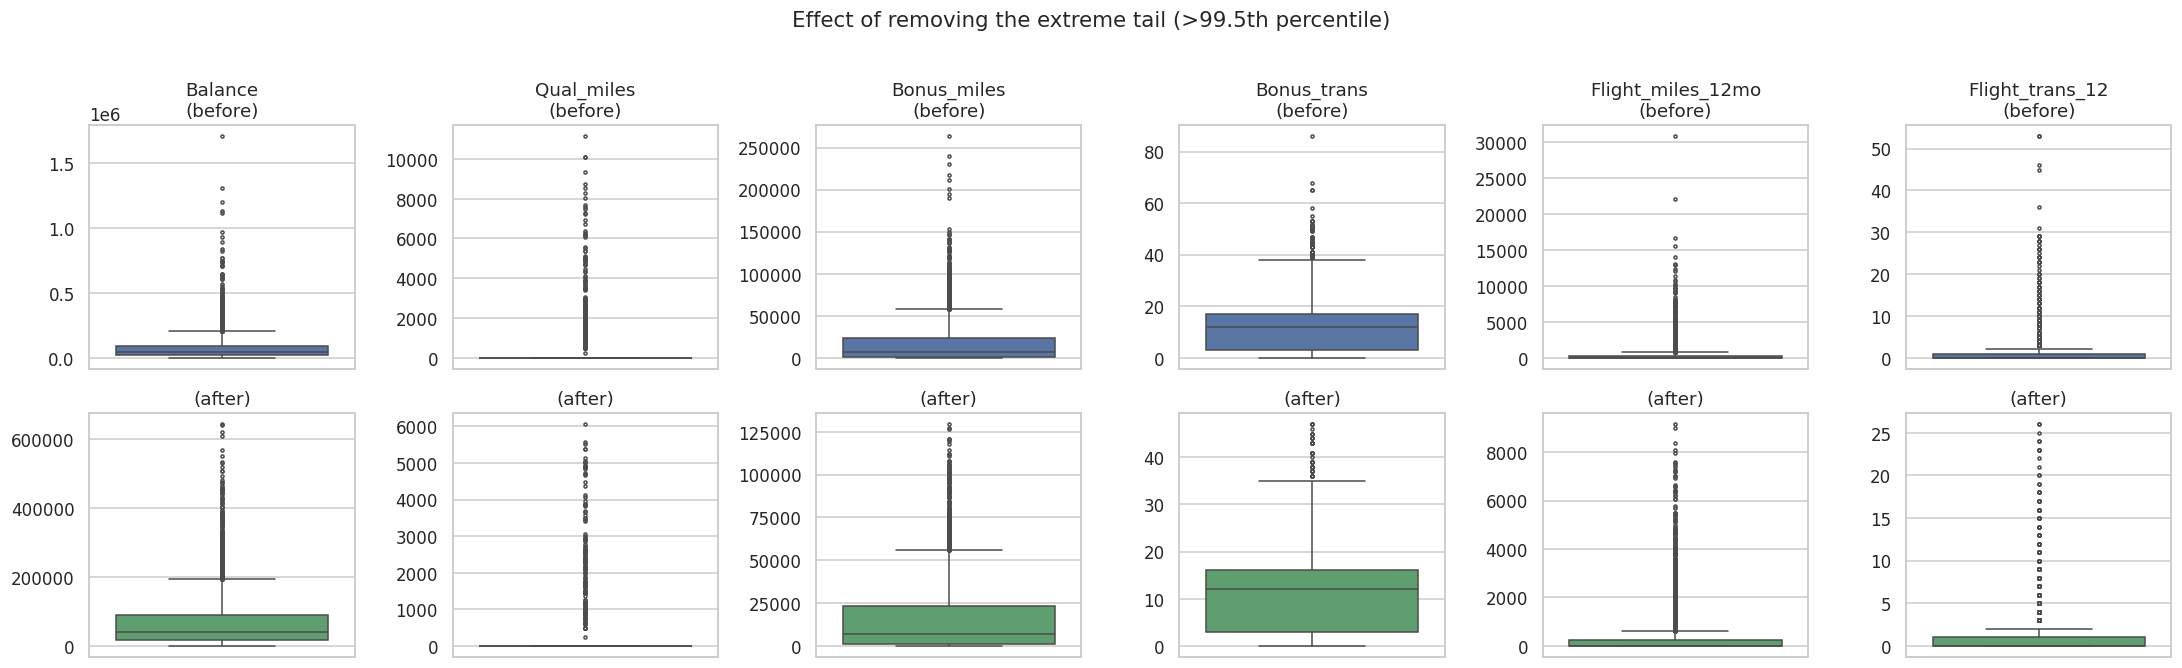

In [8]:
continuous = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]

outlier_mask = pd.Series(False, index=df.index)
rows = []
for c in continuous:
    cut = df[c].quantile(0.995)
    m = df[c] > cut
    outlier_mask |= m
    rows.append((c, round(cut, 1), int(m.sum())))
print(pd.DataFrame(rows, columns=["feature", "99.5th pct cutoff", "rows above"]).to_string(index=False))
print(f"\nRows removed in total: {outlier_mask.sum()} of {len(df)} ({outlier_mask.mean():.1%})")

fig, axes = plt.subplots(2, 6, figsize=(20, 6))
clean_tmp = df[~outlier_mask]
for i, c in enumerate(continuous):
    sns.boxplot(y=df[c], ax=axes[0, i], color=PALETTE[0], fliersize=2)
    axes[0, i].set_title(f"{c}\n(before)")
    sns.boxplot(y=clean_tmp[c], ax=axes[1, i], color=PALETTE[2], fliersize=2)
    axes[1, i].set_title("(after)")
    axes[0, i].set_ylabel(""); axes[1, i].set_ylabel("")
plt.suptitle("Effect of removing the extreme tail (>99.5th percentile)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

In [9]:
df_clean = df[~outlier_mask].reset_index(drop=True)
ids_clean = ids[~outlier_mask].reset_index(drop=True)
print("Clean dataset:", df_clean.shape)

Clean dataset: (3901, 11)


### 2.3 Feature scaling

K-Means, hierarchical (Ward) and DBSCAN are all distance based. `Balance` is in the hundreds of thousands while `cc2_miles` is between 1 and 3, so without scaling the large-valued variables would completely dominate. We standardise every feature to mean 0 and standard deviation 1.

In [10]:
scaler = StandardScaler()
X = scaler.fit_transform(df_clean[features])
X_df = pd.DataFrame(X, columns=features)
print("Scaled means :", X_df.mean().round(3).unique())
print("Scaled stds  :", X_df.std().round(3).unique())
X_df.head()

Scaled means : [-0.]
Scaled stds  : [1.]


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.511117,-0.187595,-0.763467,-0.09948,-0.057334,-0.755413,-1.145727,-0.380435,-0.398112,1.411319,-0.747348
1,-0.627054,-0.187595,-0.763467,-0.09948,-0.057334,-0.753450,-1.032881,-0.380435,-0.398112,1.395765,-0.747348
2,-0.339004,-0.187595,-0.763467,-0.09948,-0.057334,-0.566316,-0.807189,-0.380435,-0.398112,1.427845,-0.747348
3,-0.685263,-0.187595,-0.763467,-0.09948,-0.057334,-0.739803,-1.145727,-0.380435,-0.398112,1.387988,-0.747348
4,0.395753,-0.187595,1.448130,-0.09948,-0.057334,1.309666,1.675416,1.768190,1.022130,1.379725,1.338064


## 3. Exploratory data analysis
### 3.1 Distributions

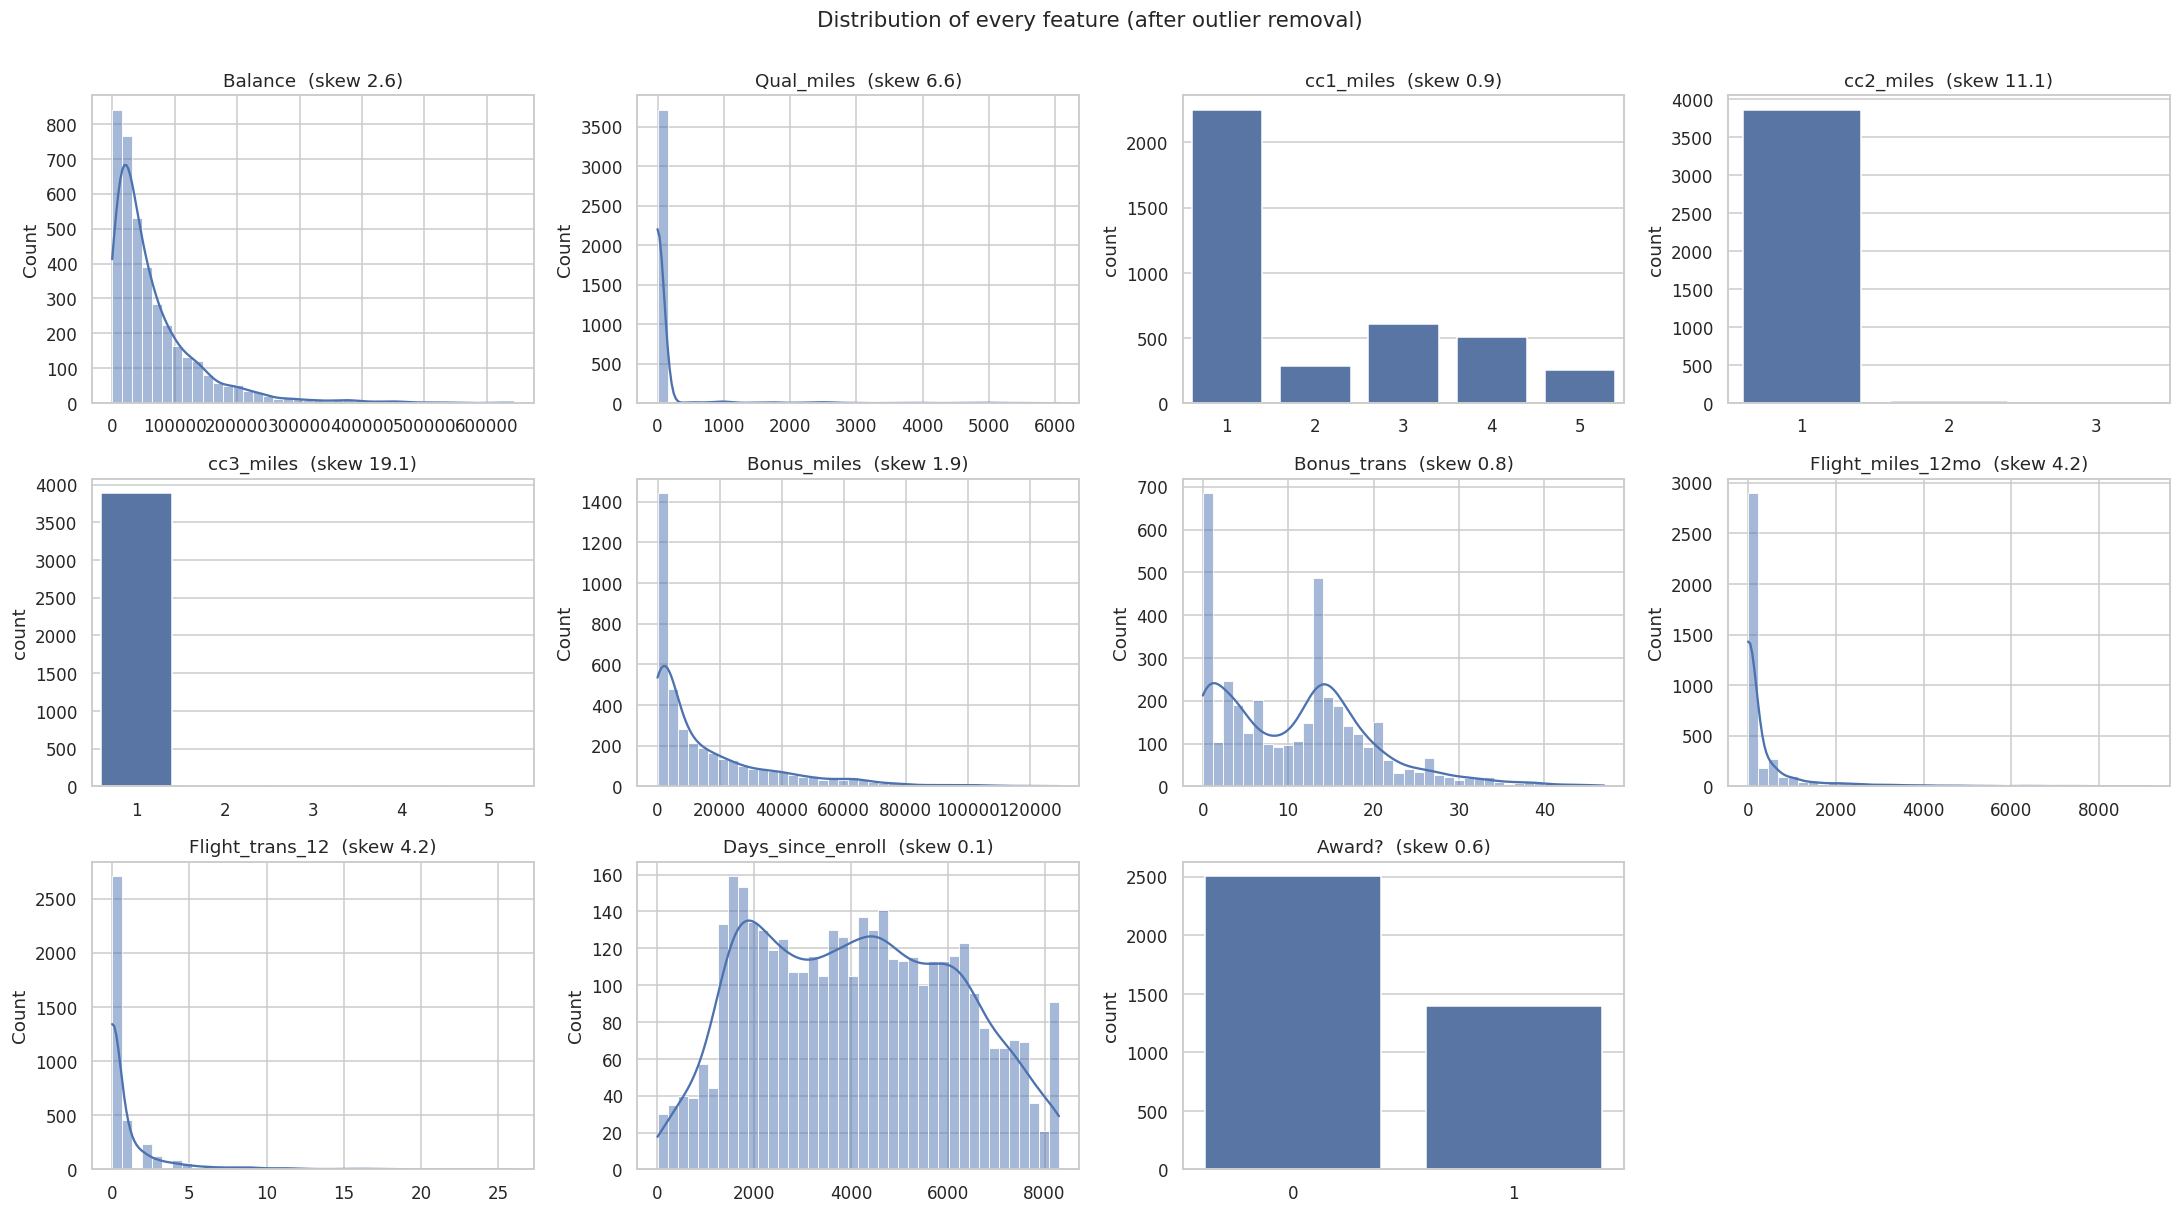

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), features):
    if df_clean[c].nunique() <= 6:
        sns.countplot(x=df_clean[c], ax=ax, color=PALETTE[0])
    else:
        sns.histplot(df_clean[c], bins=40, kde=True, ax=ax, color=PALETTE[0])
    ax.set_title(f"{c}  (skew {df_clean[c].skew():.1f})")
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of every feature (after outlier removal)", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

**Observations**
- `Balance` and `Bonus_miles` are strongly right-skewed: many customers have small values and a long tail of heavy users. `Bonus_trans` is **bimodal**, with one group making almost no bonus transactions and a second group centred around 14 to 15.
- `Qual_miles`, `Flight_miles_12mo`, `Flight_trans_12` are **zero-inflated**: most customers did not fly at all in the last 12 months, so the "flyer" group is a minority.
- `cc2_miles` and `cc3_miles` are almost constant (nearly everyone is in bin 1), so only a small fraction hold those cards. `cc1_miles` is far more varied.
- `Days_since_enroll` is spread over a broad plateau (about 1,500 to 7,000 days), i.e. customers joined steadily over many years; there are few very recent members.

### 3.2 Correlations

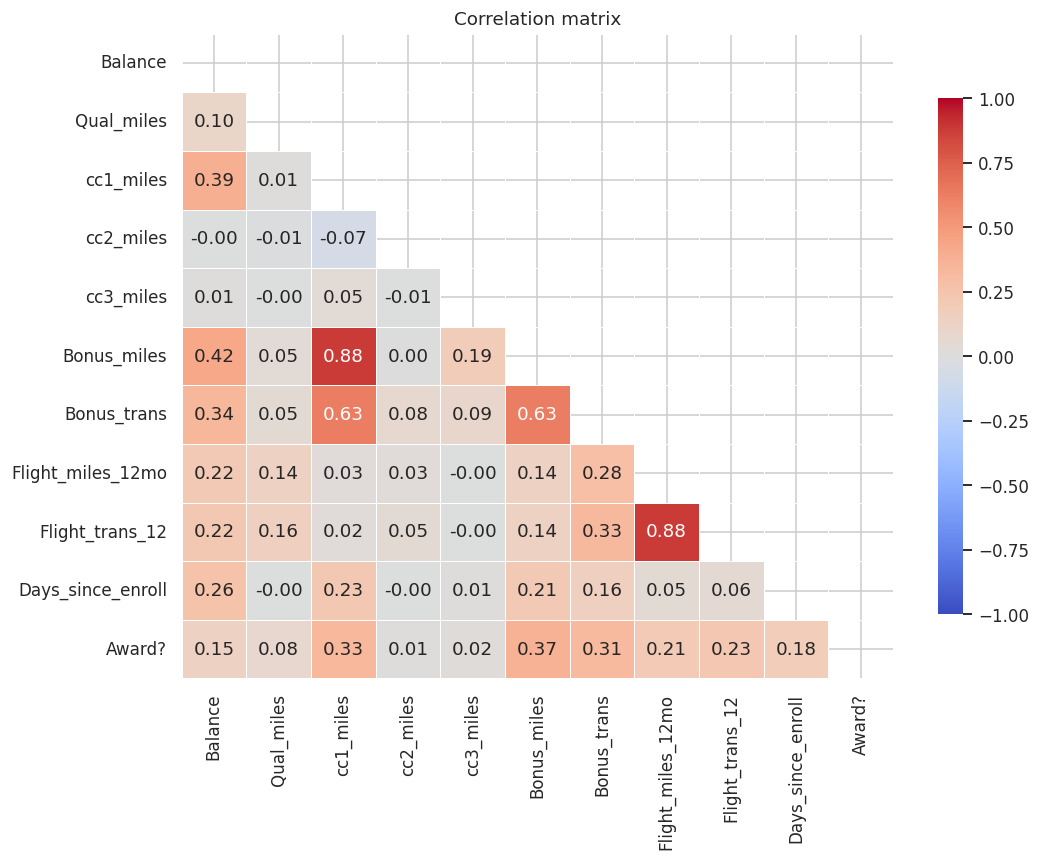

In [12]:
plt.figure(figsize=(10, 8))
corr = df_clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

In [13]:
pairs = (corr.where(~mask).stack().rename("corr").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs"] = pairs["corr"].abs()
pairs.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(3).reset_index(drop=True)

,feature_1,feature_2,corr
0,Bonus_miles,cc1_miles,0.881
1,Flight_trans_12,Flight_miles_12mo,0.876
2,Bonus_trans,cc1_miles,0.630
3,Bonus_trans,Bonus_miles,0.627
4,Bonus_miles,Balance,0.424
5,cc1_miles,Balance,0.387
6,Award?,Bonus_miles,0.372
7,Bonus_trans,Balance,0.339


The strongest relationships are intuitive. `Bonus_miles` is tightly linked to the credit-card bin `cc1_miles` (0.88) and to `Bonus_trans`, and `Flight_miles_12mo` is almost the same signal as `Flight_trans_12` (0.88). `Balance` correlates moderately with the bonus/card variables, and the award flag goes with bonus miles. Overall the variables fall into two largely independent groups, **card / bonus-transaction activity** and **actual flying**, with `Balance` and `Award?` loosely tied to the first. Because correlated features are counted several times in a distance, this also means the card-spending behaviour will weigh more heavily in the clusters than flying.

### 3.3 Relationships between key variables

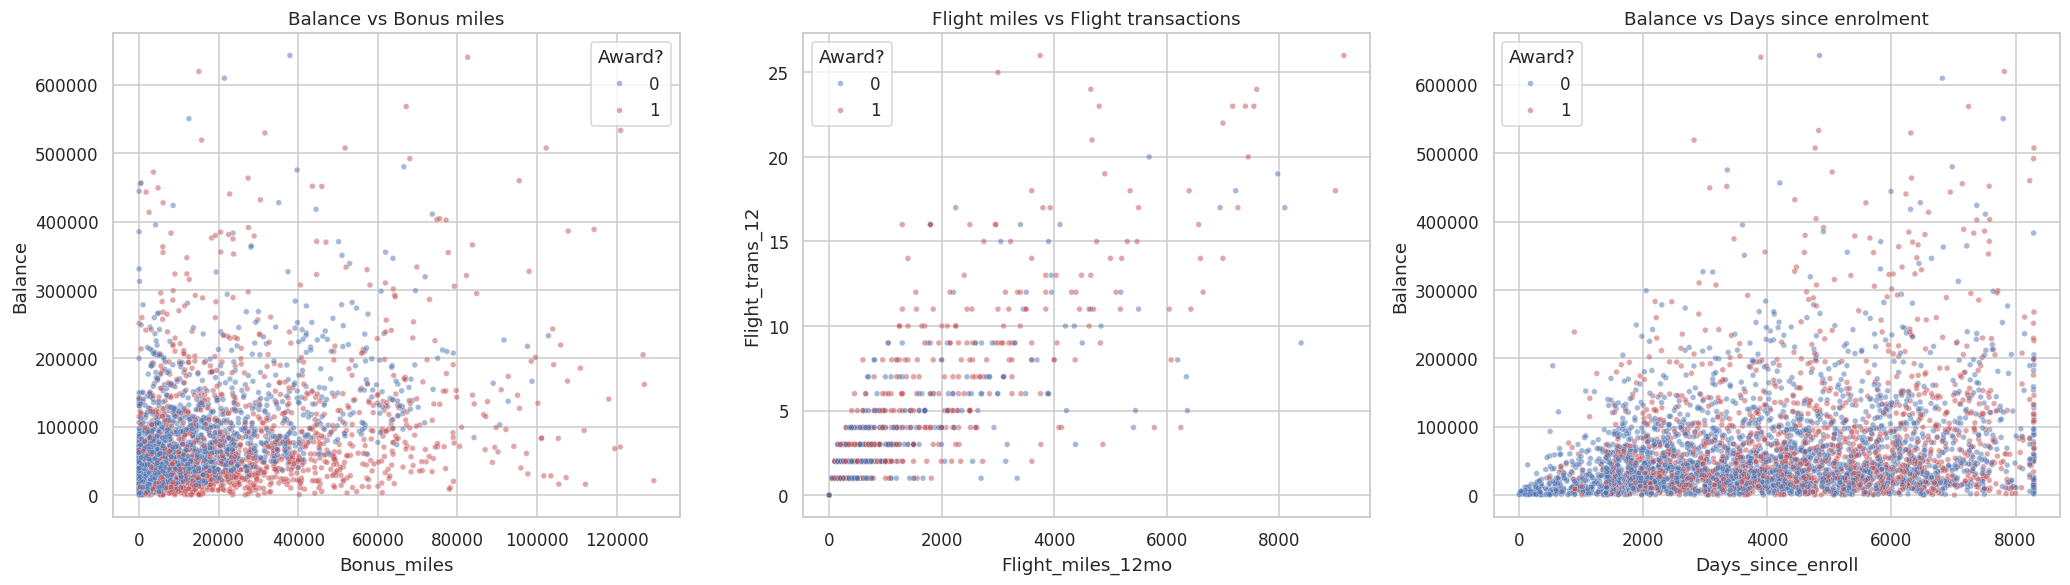

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(data=df_clean, x="Bonus_miles", y="Balance", hue="Award?", palette=[PALETTE[0], PALETTE[3]],
                alpha=.5, s=14, ax=axes[0])
axes[0].set_title("Balance vs Bonus miles")
sns.scatterplot(data=df_clean, x="Flight_miles_12mo", y="Flight_trans_12", hue="Award?",
                palette=[PALETTE[0], PALETTE[3]], alpha=.5, s=14, ax=axes[1])
axes[1].set_title("Flight miles vs Flight transactions")
sns.scatterplot(data=df_clean, x="Days_since_enroll", y="Balance", hue="Award?",
                palette=[PALETTE[0], PALETTE[3]], alpha=.5, s=14, ax=axes[2])
axes[2].set_title("Balance vs Days since enrolment")
plt.tight_layout(); plt.show()

### 3.4 Credit-card usage and award redemption

Overall award rate: 35.8%
Customers who flew in last 12 months: 30.7%
Customers with any bonus miles: 87.8%


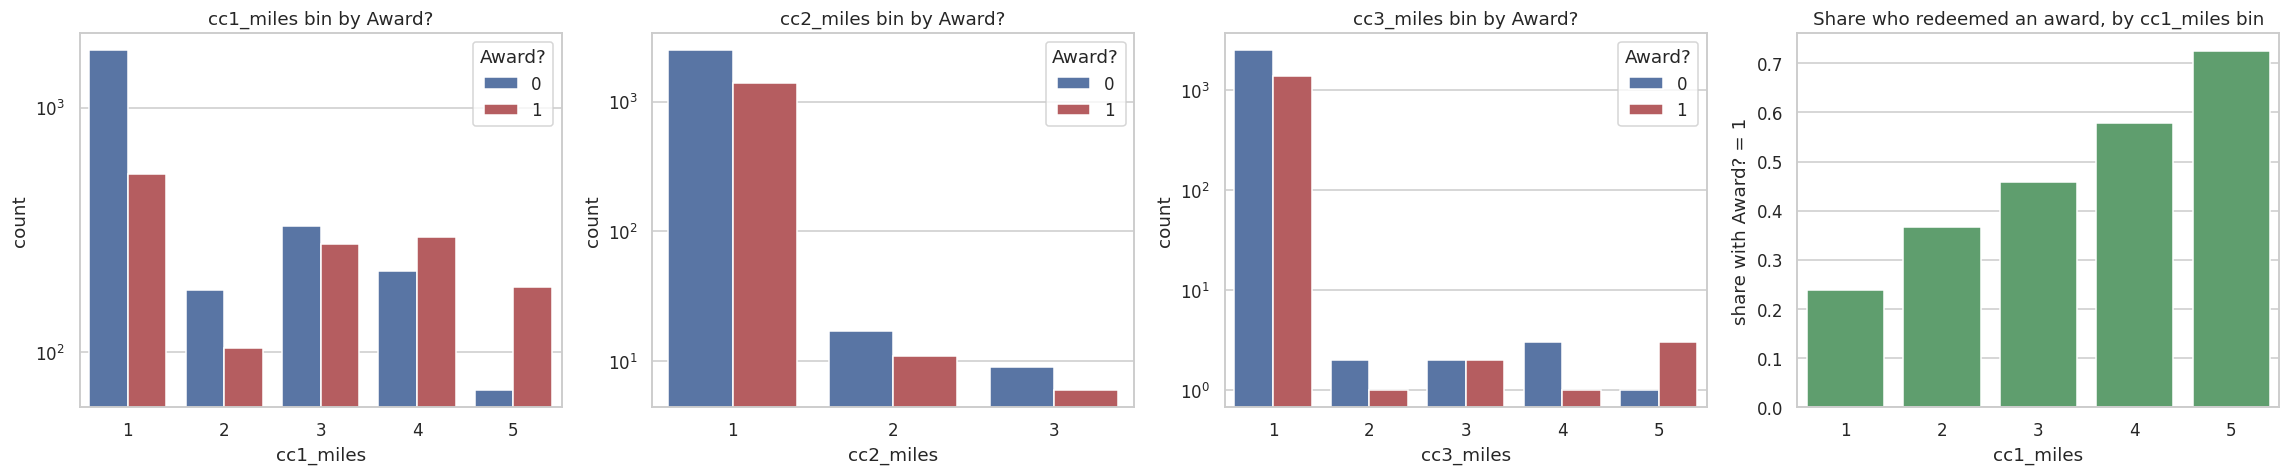

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, c in zip(axes[:3], ["cc1_miles", "cc2_miles", "cc3_miles"]):
    sns.countplot(x=df_clean[c], hue=df_clean["Award?"], palette=[PALETTE[0], PALETTE[3]], ax=ax)
    ax.set_title(f"{c} bin by Award?")
    ax.set_yscale("log")
share = df_clean.groupby("cc1_miles")["Award?"].mean()
sns.barplot(x=share.index, y=share.values, color=PALETTE[2], ax=axes[3])
axes[3].set_title("Share who redeemed an award, by cc1_miles bin")
axes[3].set_ylabel("share with Award? = 1")
plt.tight_layout(); plt.show()
print(f"Overall award rate: {df_clean['Award?'].mean():.1%}")
print(f"Customers who flew in last 12 months: {(df_clean['Flight_trans_12'] > 0).mean():.1%}")
print(f"Customers with any bonus miles: {(df_clean['Bonus_miles'] > 0).mean():.1%}")

### 3.5 Looking for structure: PCA projection

To see whether natural groups exist, we project the 11 standardised features onto 2 principal components. We reuse this projection for all cluster plots below.

Explained variance ratio: [0.295 0.164] | total: 0.459


,PC1,PC2
Bonus_miles,0.47,-0.28
Bonus_trans,0.44,-0.06
cc1_miles,0.44,-0.36
Balance,0.33,-0.03
Award?,0.30,0.02
Flight_trans_12,0.28,0.60
Flight_miles_12mo,0.27,0.60
Days_since_enroll,0.20,-0.12
Qual_miles,0.08,0.20
cc3_miles,0.07,-0.10


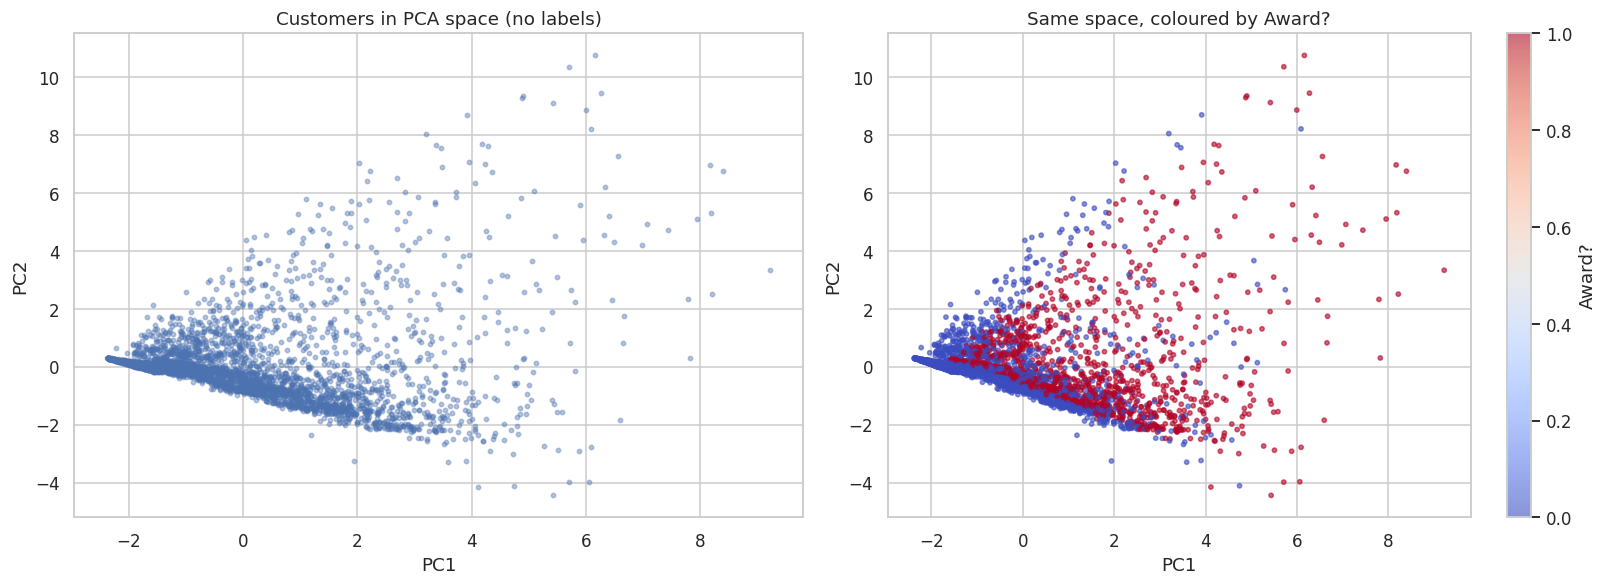

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(2)
display(loadings.sort_values("PC1", key=abs, ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(Z[:, 0], Z[:, 1], s=8, alpha=.4, color=PALETTE[0])
axes[0].set_title("Customers in PCA space (no labels)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], s=8, alpha=.6, c=df_clean["Award?"], cmap="coolwarm")
axes[1].set_title("Same space, coloured by Award?")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[1], label="Award?")
plt.tight_layout(); plt.show()

There is **no clean gap between groups**. The customers form one wedge-shaped cloud that is very dense in the lower left (low activity) and thins out towards high PC1 / PC2. PC1 is essentially an "engagement" axis (bonus miles, card use, balance, award) and PC2 a "flying" axis (flight miles and transactions). The `Award?` colouring shows that redeemers sit mostly further right along PC1. Since the groups touch each other, we should expect moderate (not spectacular) silhouette scores, and density-based clustering in particular will find it hard to separate groups that overlap.

## 4. K-Means clustering

### 4.1 Choosing K: elbow curve and silhouette

,k,inertia (WCSS),silhouette,davies_bouldin,calinski_harabasz
0,2,34193.524,0.318,1.612,994.033
1,3,29396.227,0.308,1.387,896.045
2,4,25816.711,0.308,1.140,860.120
3,5,23682.145,0.257,1.294,790.845
4,6,21704.521,0.237,1.376,761.125
5,7,18169.460,0.240,1.210,883.785
6,8,16339.936,0.286,1.114,904.368
7,9,15099.956,0.245,1.119,896.034
8,10,14078.768,0.255,1.098,885.385


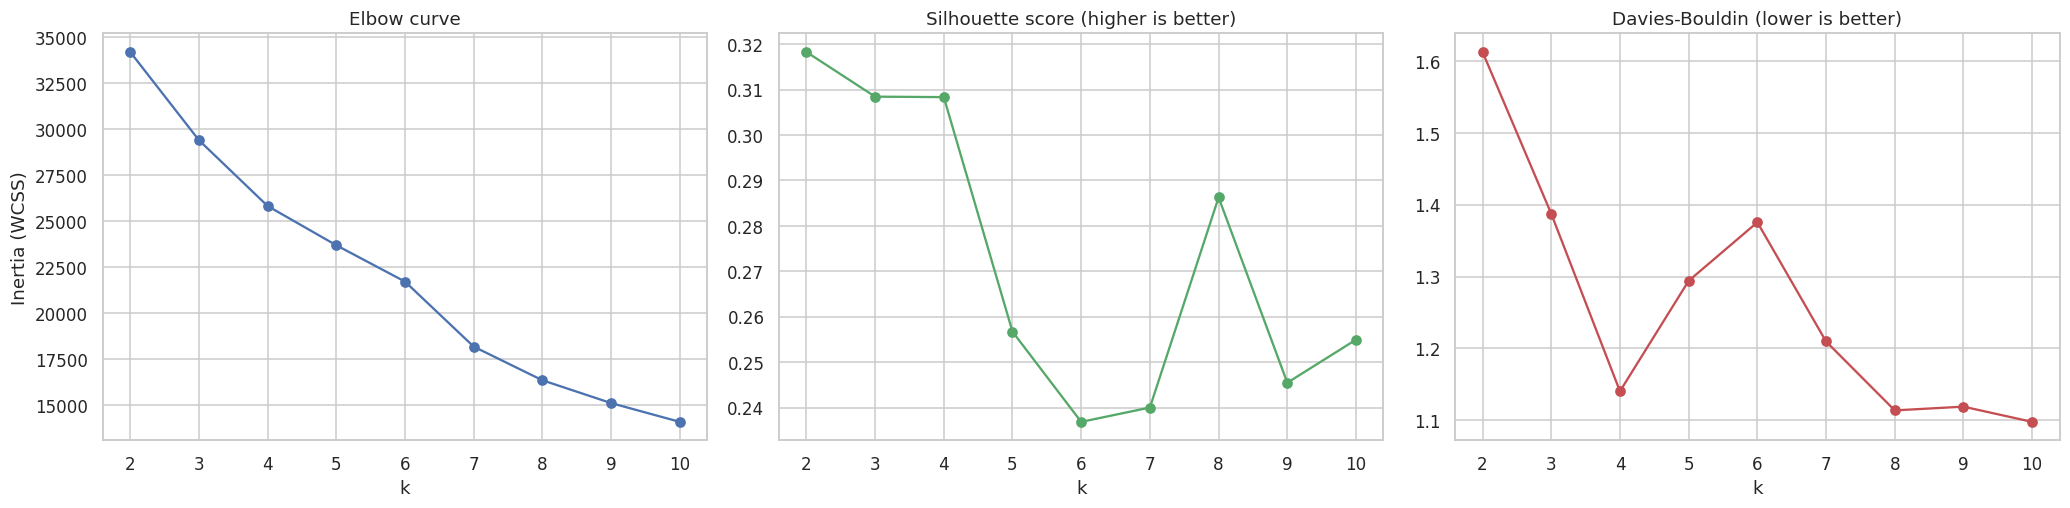

In [17]:
K_RANGE = range(2, 11)
inertia, sil, dbi, chi = [], [], [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    dbi.append(davies_bouldin_score(X, km.labels_))
    chi.append(calinski_harabasz_score(X, km.labels_))

kmeans_scores = pd.DataFrame({"k": list(K_RANGE), "inertia (WCSS)": inertia, "silhouette": sil,
                              "davies_bouldin": dbi, "calinski_harabasz": chi}).round(3)
display(kmeans_scores)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
axes[0].plot(list(K_RANGE), inertia, "o-", color=PALETTE[0])
axes[0].set_title("Elbow curve"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(list(K_RANGE), sil, "o-", color=PALETTE[2])
axes[1].set_title("Silhouette score (higher is better)"); axes[1].set_xlabel("k")
axes[2].plot(list(K_RANGE), dbi, "o-", color=PALETTE[3])
axes[2].set_title("Davies-Bouldin (lower is better)"); axes[2].set_xlabel("k")
for ax in axes: ax.set_xticks(list(K_RANGE))
plt.tight_layout(); plt.show()

**Reading the curves.** The elbow is gradual (no sharp kink), but the drop in inertia flattens noticeably after k = 3 to 4. Silhouette is highest at k = 2 and almost identical at k = 3 and k = 4 (about 0.31), then falls for k >= 5. k = 2 would only split "flyers/spenders" from the rest, which is too coarse for marketing, so we use **k = 3**, the smallest value that gives a richer segmentation while keeping a near-best silhouette. We also show k = 4 below as a sensitivity check.

### 4.2 Final K-Means model (k = 3)

In [18]:
K_FINAL = 3
km = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(X)
df_clean["KMeans"] = km.labels_

print("Cluster sizes:")
print(df_clean["KMeans"].value_counts().sort_index().to_string())
print(f"\nSilhouette score    : {silhouette_score(X, km.labels_):.3f}")
print(f"Davies-Bouldin index: {davies_bouldin_score(X, km.labels_):.3f}")

Cluster sizes:
KMeans
0    2434
1    1247
2     220

Silhouette score    : 0.308
Davies-Bouldin index: 1.387


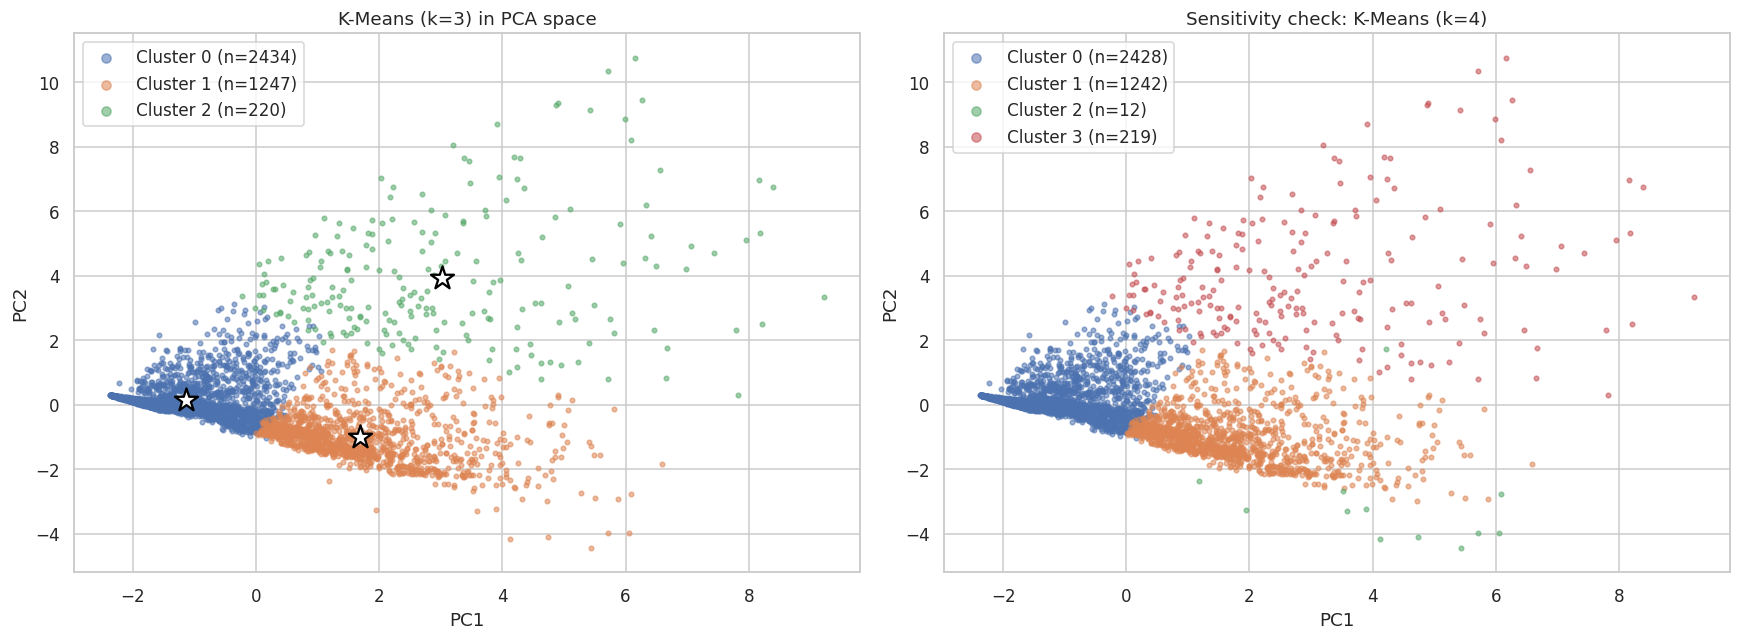

In [19]:
def plot_clusters(labels, title, ax=None, noise_label=-1):
    ax = ax or plt.gca()
    for i, lab in enumerate(sorted(set(labels))):
        m = labels == lab
        if lab == noise_label:
            ax.scatter(Z[m, 0], Z[m, 1], s=14, c="black", marker="x", alpha=.6, label=f"Noise (n={m.sum()})")
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=.55, color=PALETTE[i % len(PALETTE)], label=f"Cluster {lab} (n={m.sum()})")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(markerscale=2, loc="best")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_clusters(df_clean["KMeans"].values, "K-Means (k=3) in PCA space", axes[0])
cent = pca.transform(km.cluster_centers_)
axes[0].scatter(cent[:, 0], cent[:, 1], s=250, c="white", edgecolor="black", marker="*", linewidth=1.5, zorder=5)

km4 = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(X)
plot_clusters(km4.labels_, "Sensitivity check: K-Means (k=4)", axes[1])
plt.tight_layout(); plt.show()

### 4.3 Silhouette plot for K-Means (k = 3)

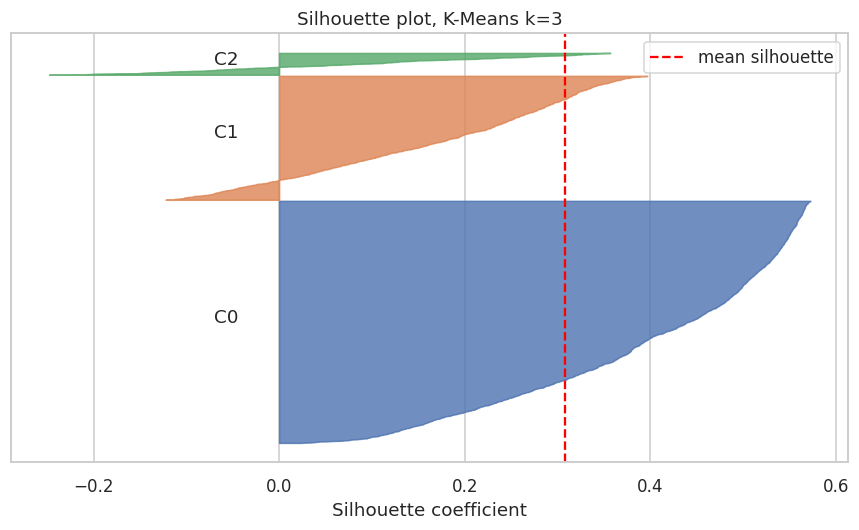

In [20]:
from sklearn.metrics import silhouette_samples
sv = silhouette_samples(X, km.labels_)
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
for i in range(K_FINAL):
    v = np.sort(sv[km.labels_ == i])
    y_upper = y_lower + len(v)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, v, color=PALETTE[i], alpha=.8)
    ax.text(-0.07, y_lower + .5 * len(v), f"C{i}")
    y_lower = y_upper + 10
ax.axvline(silhouette_score(X, km.labels_), color="red", ls="--", label="mean silhouette")
ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([]); ax.set_title("Silhouette plot, K-Means k=3")
ax.legend(); plt.tight_layout(); plt.show()

### 4.4 Cluster profile (original units)

,size,share_%,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
KMeans,,,,,,,,,,,,,
0,2434,62.4,41164.0,71.0,1.2,1.0,1.0,4309.0,6.7,142.9,0.5,3701.5,0.2
1,1247,32.0,107527.1,94.9,3.7,1.0,1.0,37213.5,18.2,243.3,0.7,4811.4,0.6
2,220,5.6,129774.6,446.1,1.9,1.0,1.0,24209.9,20.6,3561.2,10.4,4413.3,0.7


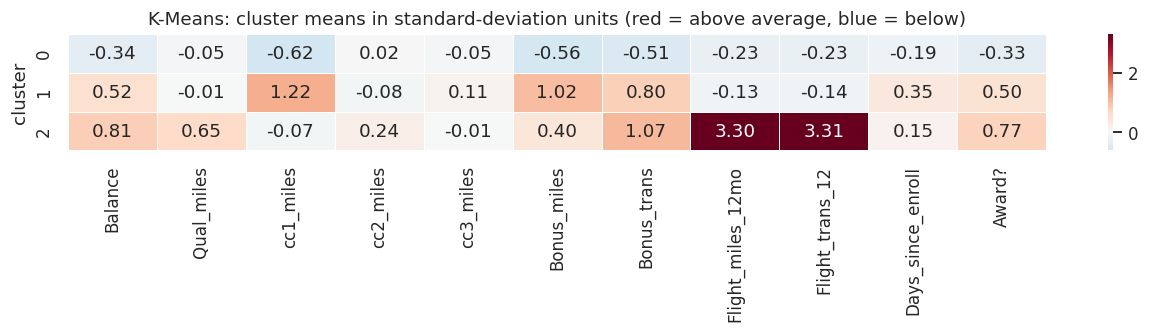

In [21]:
def profile(labels_col, data=df_clean):
    g = data.groupby(labels_col)[features]
    p = g.mean().round(1)
    p.insert(0, "size", data[labels_col].value_counts().sort_index())
    p.insert(1, "share_%", (p["size"] / len(data) * 100).round(1))
    return p

km_profile = profile("KMeans")
display(km_profile)

# standardised heatmap makes the differences easy to read
z_prof = pd.DataFrame(X, columns=features).groupby(df_clean["KMeans"].values).mean()
plt.figure(figsize=(12, 3.2))
sns.heatmap(z_prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5)
plt.title("K-Means: cluster means in standard-deviation units (red = above average, blue = below)")
plt.ylabel("cluster"); plt.tight_layout(); plt.show()

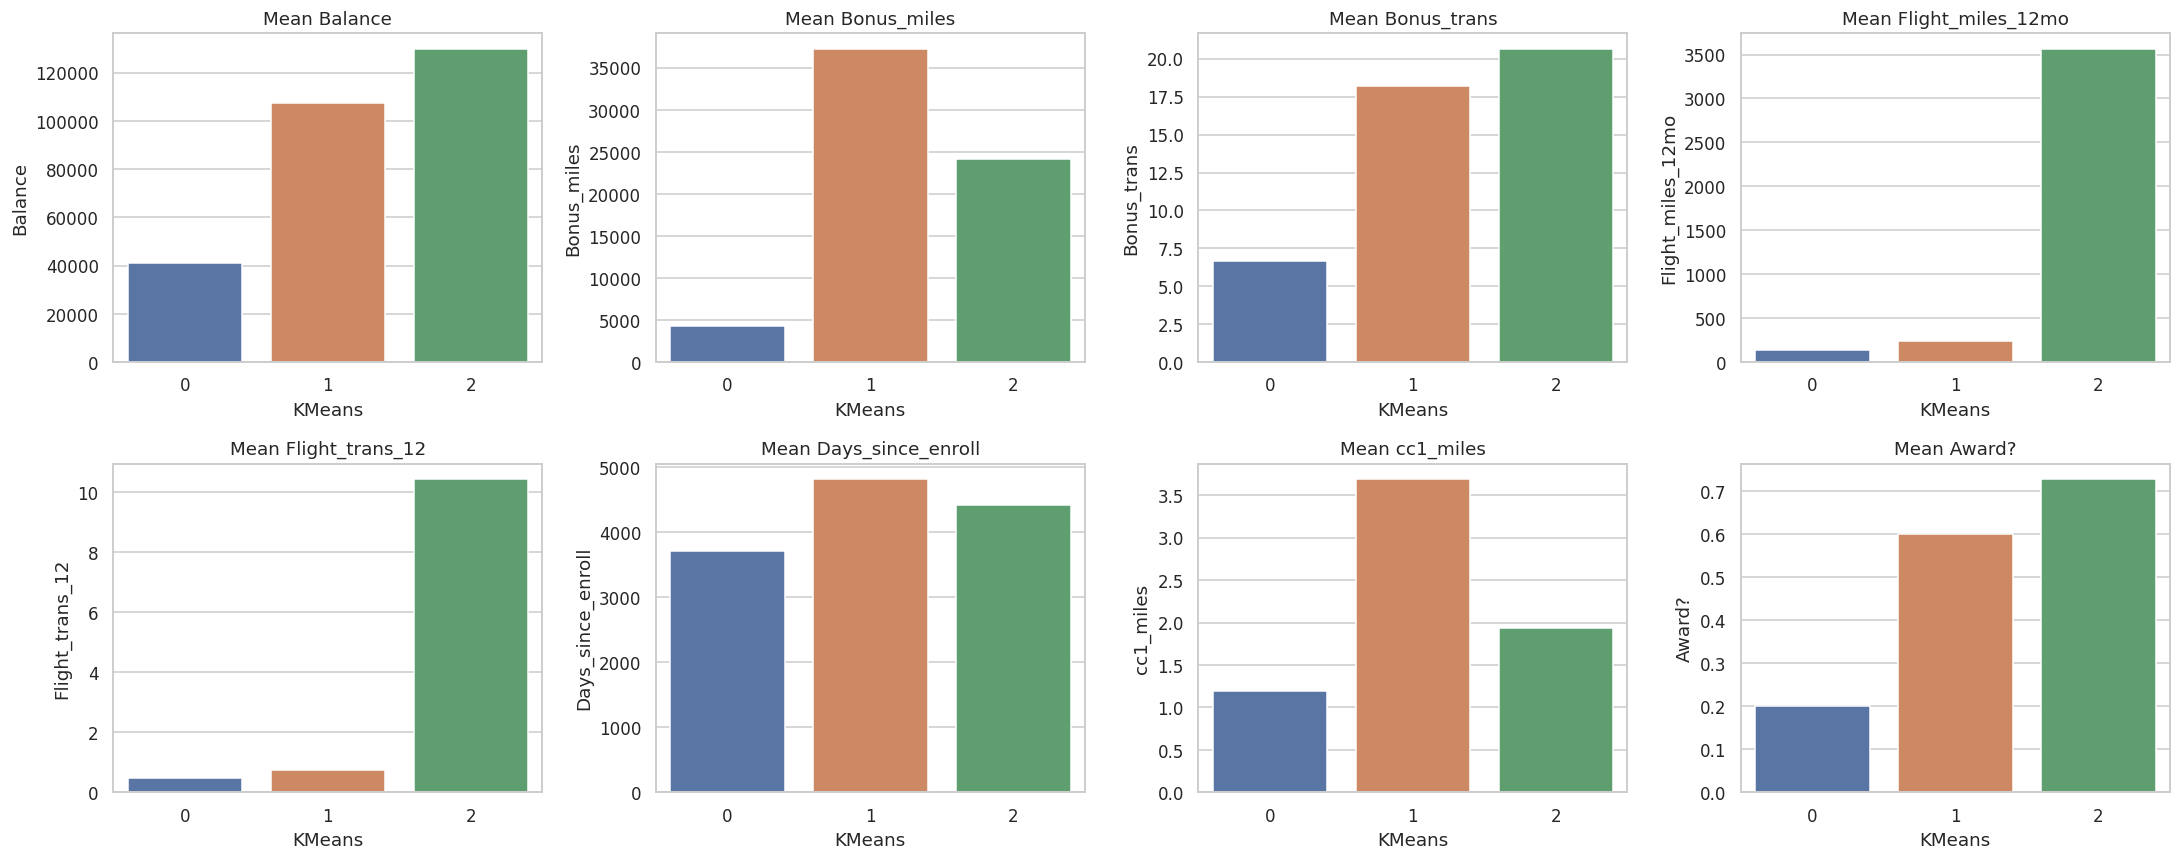

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), ["Balance", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo",
                                "Flight_trans_12", "Days_since_enroll", "cc1_miles", "Award?"]):
    sns.barplot(data=df_clean, x="KMeans", y=c, palette=PALETTE[:K_FINAL], ax=ax, errorbar=None)
    ax.set_title(f"Mean {c}")
plt.tight_layout(); plt.show()

### 4.5 Interpretation of the K-Means segments

| Cluster | Size | What characterises it | Suggested label |
|---|---|---|---|
| **0** | 62 % | Lowest balance (about 41k miles), almost no card miles (`cc1_miles` ~ 1.2), few bonus miles (about 4k) and bonus transactions (about 7), little flying (about 140 miles a year), the **newest members** (about 3,700 days) and only about 20 % have ever redeemed an award | **Low-engagement / casual members** |
| **1** | 32 % | High balance (about 108k), high credit-card bin (`cc1_miles` ~ 3.7), large bonus miles (about 37k), the **longest tenure** (about 4,800 days), 60 % redeemed an award, but they fly little (about 240 miles) | **Card-driven loyalists** (earn miles by spending, not flying) |
| **2** | 5.6 % | Very high flight activity (about 3,560 flight miles and 10 flights a year), highest qualifying miles (about 450), balance about 130k, 100 % flew in the last 12 months, 73 % redeemed an award | **Frequent flyers / premium travellers** |

**Sensitivity check.** Using k = 4 mainly carves out a tiny cluster of only 12 customers from the other groups, so it does not add a new meaningful segment, which supports keeping k = 3.

## 5. Hierarchical (agglomerative) clustering

### 5.1 Dendrograms for different linkage criteria
The linkage criterion defines the distance between two clusters:
- **Ward**: merge the pair that increases the within-cluster variance the least (compact, similar-sized clusters)
- **Complete**: maximum distance between members (compact clusters)
- **Average**: mean distance between members
- **Single**: minimum distance between members (can chain points together)

All dendrograms are truncated to the last 30 merges to stay readable.

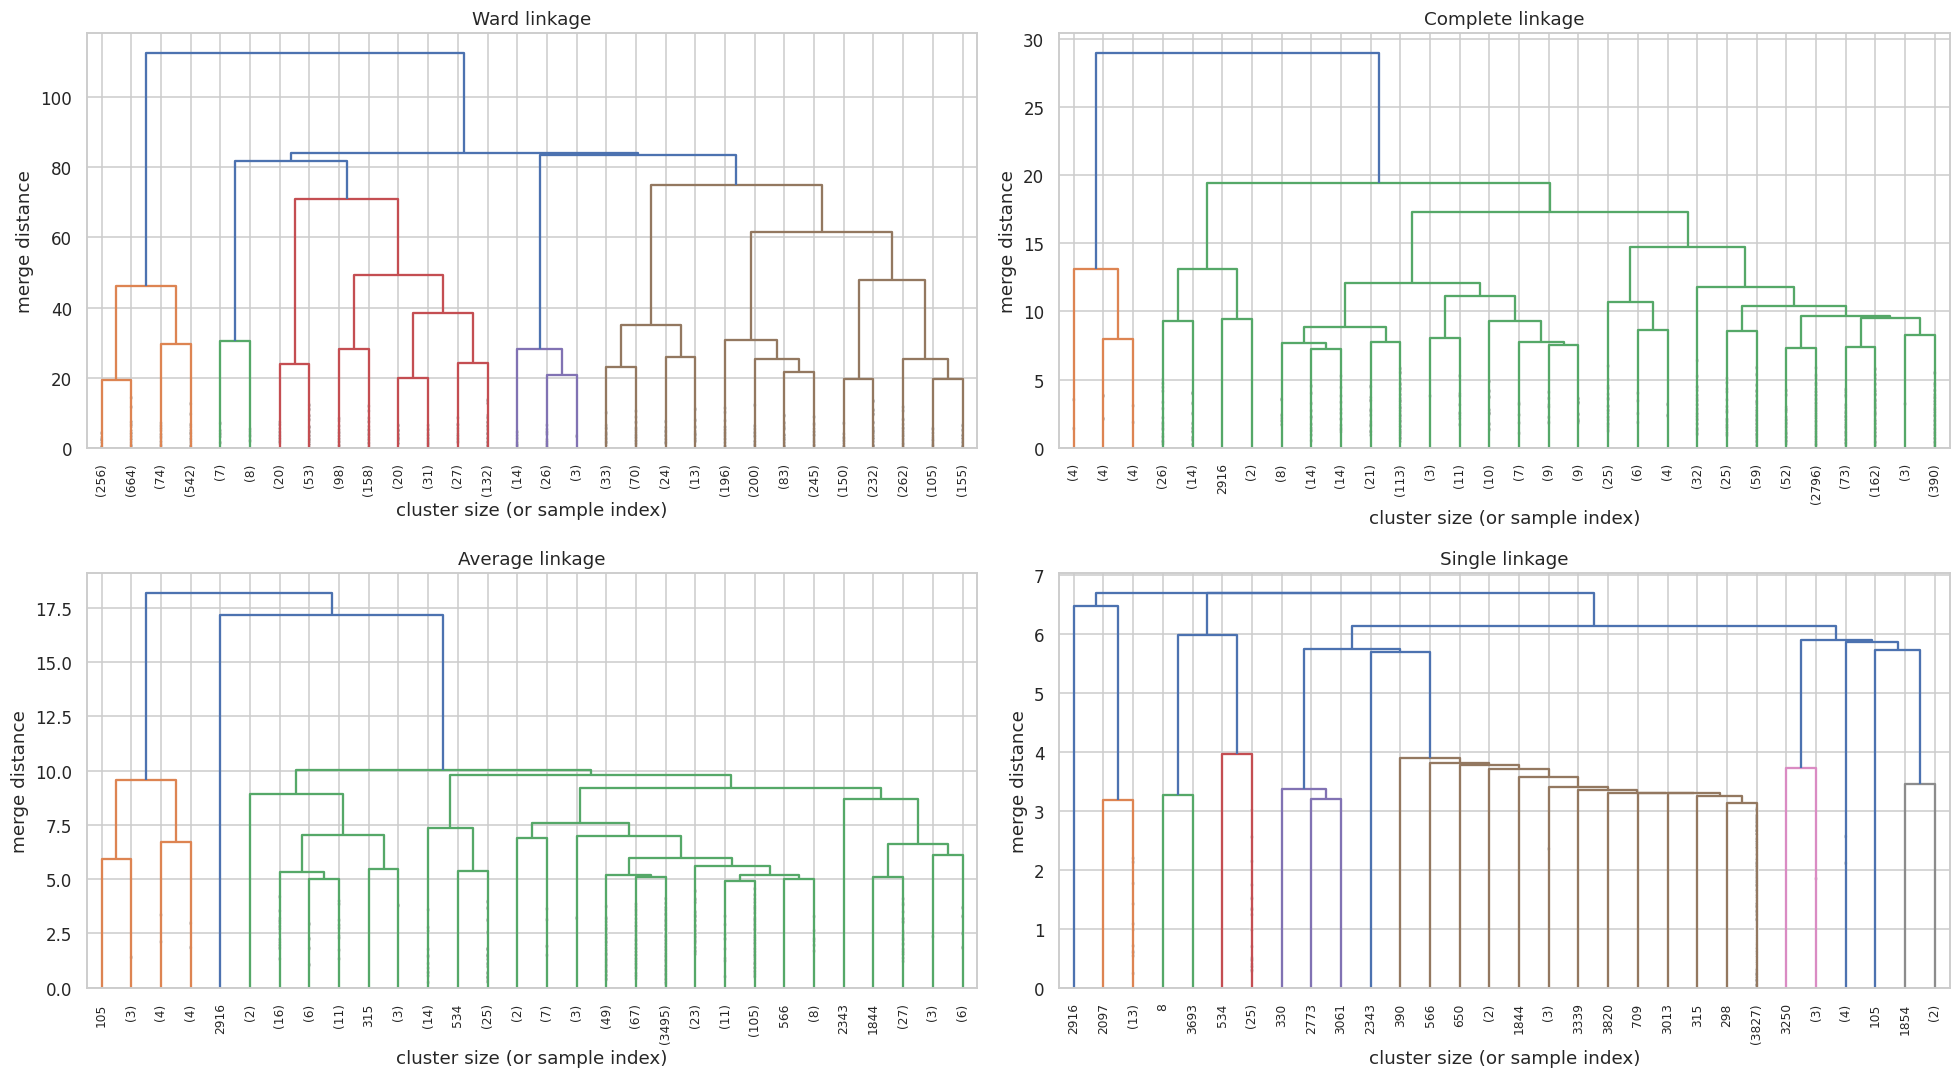

In [23]:
linkages = {}
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for ax, method in zip(axes.ravel(), ["ward", "complete", "average", "single"]):
    Lk = linkage(X, method=method)
    linkages[method] = Lk
    dendrogram(Lk, truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, leaf_font_size=8,
               show_contracted=True, color_threshold=0.7 * Lk[-1, 2])
    ax.set_title(f"{method.capitalize()} linkage")
    ax.set_xlabel("cluster size (or sample index)"); ax.set_ylabel("merge distance")
plt.tight_layout(); plt.show()

In the **Ward** dendrogram the top merge happens at a distance of about 110 and the second split at about 85, whereas almost everything below merges at 75 or less. These two large jumps suggest cutting the tree into **3 clusters**. The first split separates one group of roughly 1,500 customers from all the rest. The **single**, **average** and **complete** dendrograms are dominated by one huge branch to which a handful of extreme customers are attached at large distances: they mostly isolate outliers rather than describing segments.

### 5.2 Comparing linkage criteria and number of clusters

In [24]:
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist

dists = pdist(X)
rows = []
for method, Lk in linkages.items():
    coph = cophenet(Lk, dists)[0]
    for k in range(2, 7):
        lab = fcluster(Lk, k, criterion="maxclust")
        sizes = np.bincount(lab)[1:]
        rows.append({"linkage": method, "k": k, "silhouette": silhouette_score(X, lab),
                     "davies_bouldin": davies_bouldin_score(X, lab),
                     "largest_cluster_%": sizes.max() / len(lab) * 100,
                     "smallest_cluster_n": sizes.min(), "cophenetic_corr": coph})
link_scores = pd.DataFrame(rows).round(3)
display(link_scores.pivot(index="k", columns="linkage", values="silhouette").round(3).rename_axis(columns="Silhouette by linkage"))
display(link_scores.pivot(index="k", columns="linkage", values="largest_cluster_%").round(1).rename_axis(columns="Largest cluster, % of customers"))
display(link_scores.groupby("linkage")["cophenetic_corr"].first().to_frame("cophenetic correlation"))

Silhouette by linkage,average,complete,single,ward
k,,,,
2,0.788,0.788,0.726,0.176
3,0.770,0.631,0.527,0.176
4,0.616,0.458,0.527,0.187
5,0.608,0.466,0.534,0.194
6,0.608,0.466,0.516,0.207


"Largest cluster, % of customers",average,complete,single,ward
k,,,,
2,99.7,99.7,99.6,60.6
3,99.7,98.6,98.9,46.4
4,98.7,93.0,98.9,45.3
5,97.6,92.1,98.6,45.3
6,97.6,92.1,98.6,41.7


,cophenetic correlation
linkage,
average,0.895
complete,0.801
single,0.722
ward,0.349


**Important caveat when reading these numbers.** Single, average and complete linkage obtain *high* silhouette scores, but only because they produce **one giant cluster holding roughly 92 to 99.7 % of customers plus a few tiny outlier clusters** (see the second table). A silhouette that high with such a lopsided partition is not a useful segmentation. Ward gives much lower silhouettes (about 0.18 to 0.21) and a low cophenetic correlation (0.35), because the groups touch each other, but it produces balanced, interpretable groups, so it is the right choice for customer segmentation here. This is also consistent with Ward's objective (minimise within-cluster variance), which is the same objective as K-Means.

### 5.3 Final hierarchical model: Ward linkage, k = 3

Cluster sizes:
Hierarchical
0    1811
1    1536
2     554

Silhouette score    : 0.176
Davies-Bouldin index: 2.121


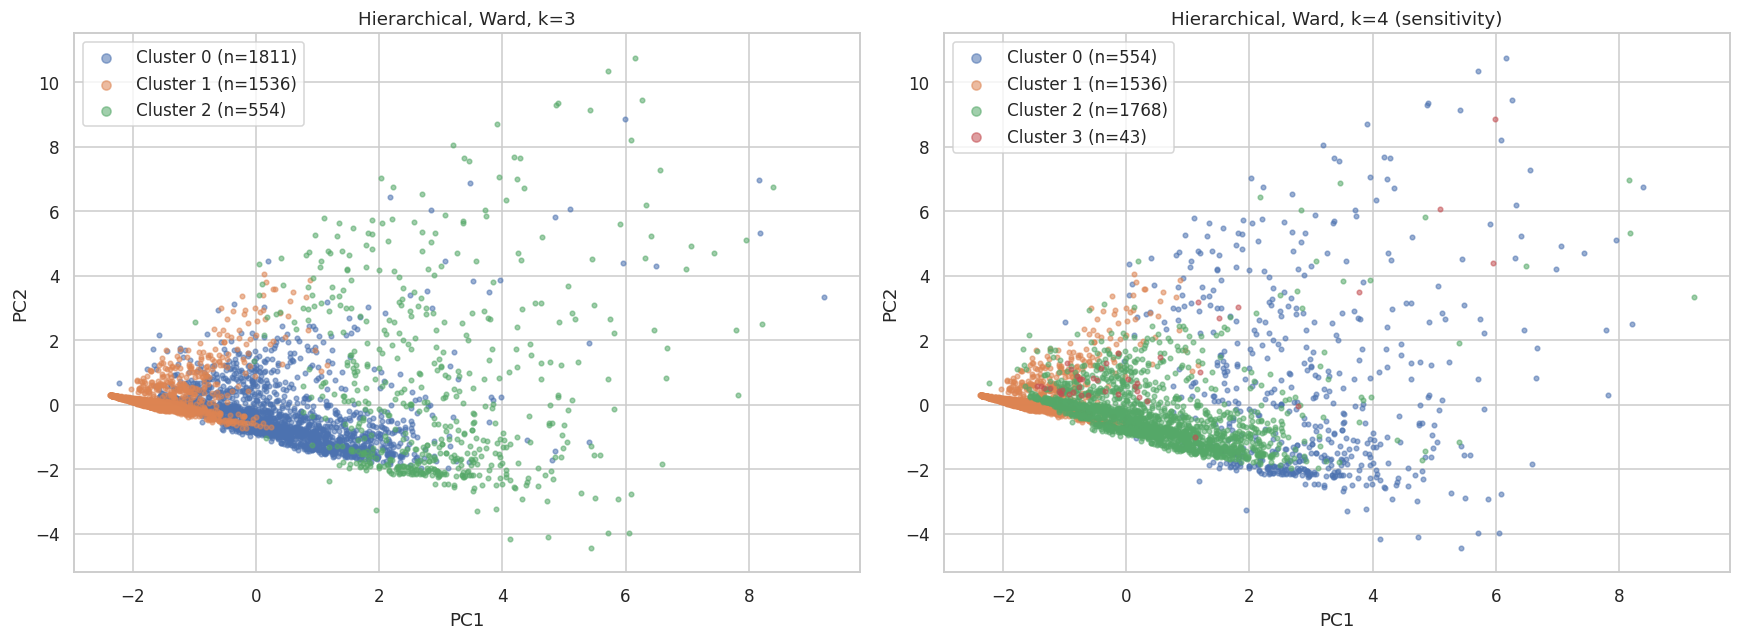

In [25]:
hc = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
df_clean["Hierarchical"] = hc.labels_
print("Cluster sizes:")
print(df_clean["Hierarchical"].value_counts().sort_index().to_string())
print(f"\nSilhouette score    : {silhouette_score(X, hc.labels_):.3f}")
print(f"Davies-Bouldin index: {davies_bouldin_score(X, hc.labels_):.3f}")

hc4 = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_clusters(hc.labels_, "Hierarchical, Ward, k=3", axes[0])
plot_clusters(hc4.labels_, "Hierarchical, Ward, k=4 (sensitivity)", axes[1])
plt.tight_layout(); plt.show()

,size,share_%,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Hierarchical,,,,,,,,,,,,,
0,1811,46.4,70980.8,191.5,2.4,1.0,1.0,18214.6,14.0,200.9,0.7,4245.9,0.6
1,1536,39.4,33234.4,3.6,1.0,1.0,1.0,2325.6,4.4,138.7,0.5,3640.6,0.0
2,554,14.2,150245.0,66.7,3.6,1.0,1.1,46319.2,20.5,1548.5,4.5,4871.5,0.7


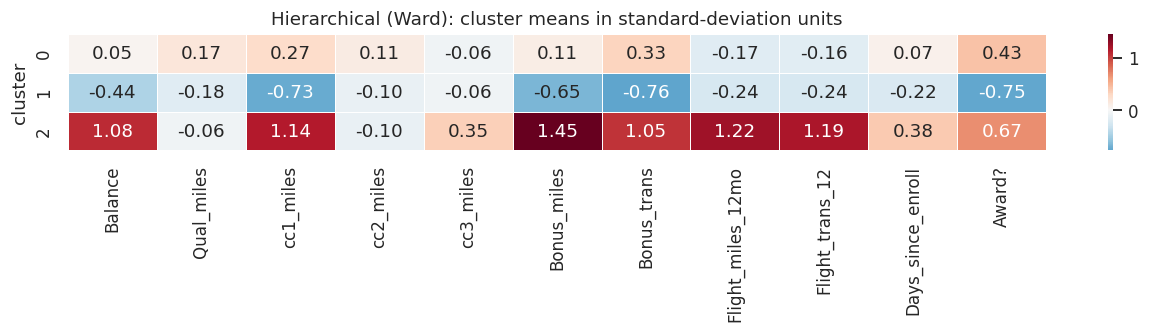

In [26]:
hc_profile = profile("Hierarchical")
display(hc_profile)
z_prof = pd.DataFrame(X, columns=features).groupby(df_clean["Hierarchical"].values).mean()
plt.figure(figsize=(12, 3.2))
sns.heatmap(z_prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5)
plt.title("Hierarchical (Ward): cluster means in standard-deviation units")
plt.ylabel("cluster"); plt.tight_layout(); plt.show()

### 5.4 Interpretation of the hierarchical (Ward) segments

| Cluster | Size | What characterises it | Suggested label |
|---|---|---|---|
| **0** | 46 % | Mid-level balance (about 71k), moderate card use (`cc1_miles` ~ 2.4), bonus miles about 18k, **56 % redeemed an award**, little flying | **Mid-tier card users who redeem** |
| **1** | 39 % | Lowest balance (about 33k), practically no card miles (`cc1_miles` ~ 1.0), very few bonus miles (about 2k), **nobody has redeemed an award**, newest members | **Inactive / non-redeeming members** |
| **2** | 14 % | Highest balance (about 150k), top card bin (~ 3.6), most bonus miles (about 46k), longest tenure, much more flying (about 1,550 flight miles, 70 % flew), 68 % redeemed | **High-value, active members** |

Ward splits the customers mainly along the **engagement and award** dimension, and it separates the heavy flyers less sharply than K-Means does (K-Means isolates a flyer-only group of 220 customers, while Ward folds most of them into cluster 2).

## 6. DBSCAN

DBSCAN needs two parameters: `eps` (neighbourhood radius) and `min_samples` (points needed to form a dense region). Points that are not in any dense region are labelled **noise** (-1).

### 6.1 Choosing eps with the k-distance graph
A common rule of thumb is `min_samples` ≈ 2 x number of features = 22. We sort the distance of each point to its k-th nearest neighbour; the "knee" suggests a suitable `eps`.

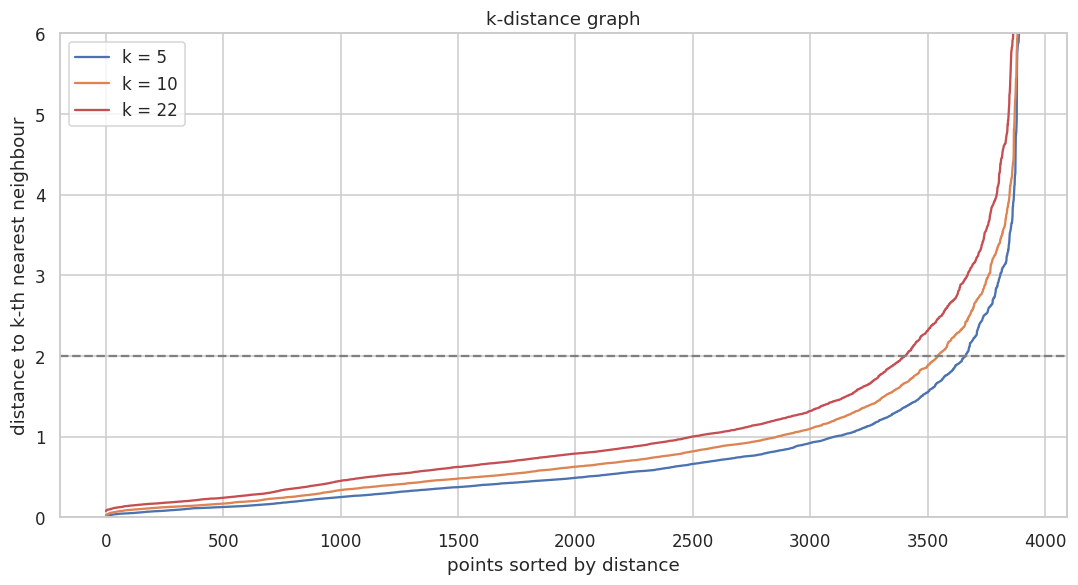

In [27]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for k, col in zip([5, 10, 22], [PALETTE[0], PALETTE[1], PALETTE[3]]):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    d, _ = nn.kneighbors(X)
    ax.plot(np.sort(d[:, -1]), label=f"k = {k}", color=col)
ax.set_ylim(0, 6); ax.set_xlabel("points sorted by distance"); ax.set_ylabel("distance to k-th nearest neighbour")
ax.set_title("k-distance graph"); ax.axhline(2.0, ls="--", color="grey"); ax.legend()
plt.tight_layout(); plt.show()

The curves rise slowly and then bend sharply upwards at a distance of roughly **1.5 to 2.0**; the knee therefore suggests `eps` somewhere in that range. We do not rely on a visual estimate alone and instead run a grid search around it.

### 6.2 Grid search over eps and min_samples

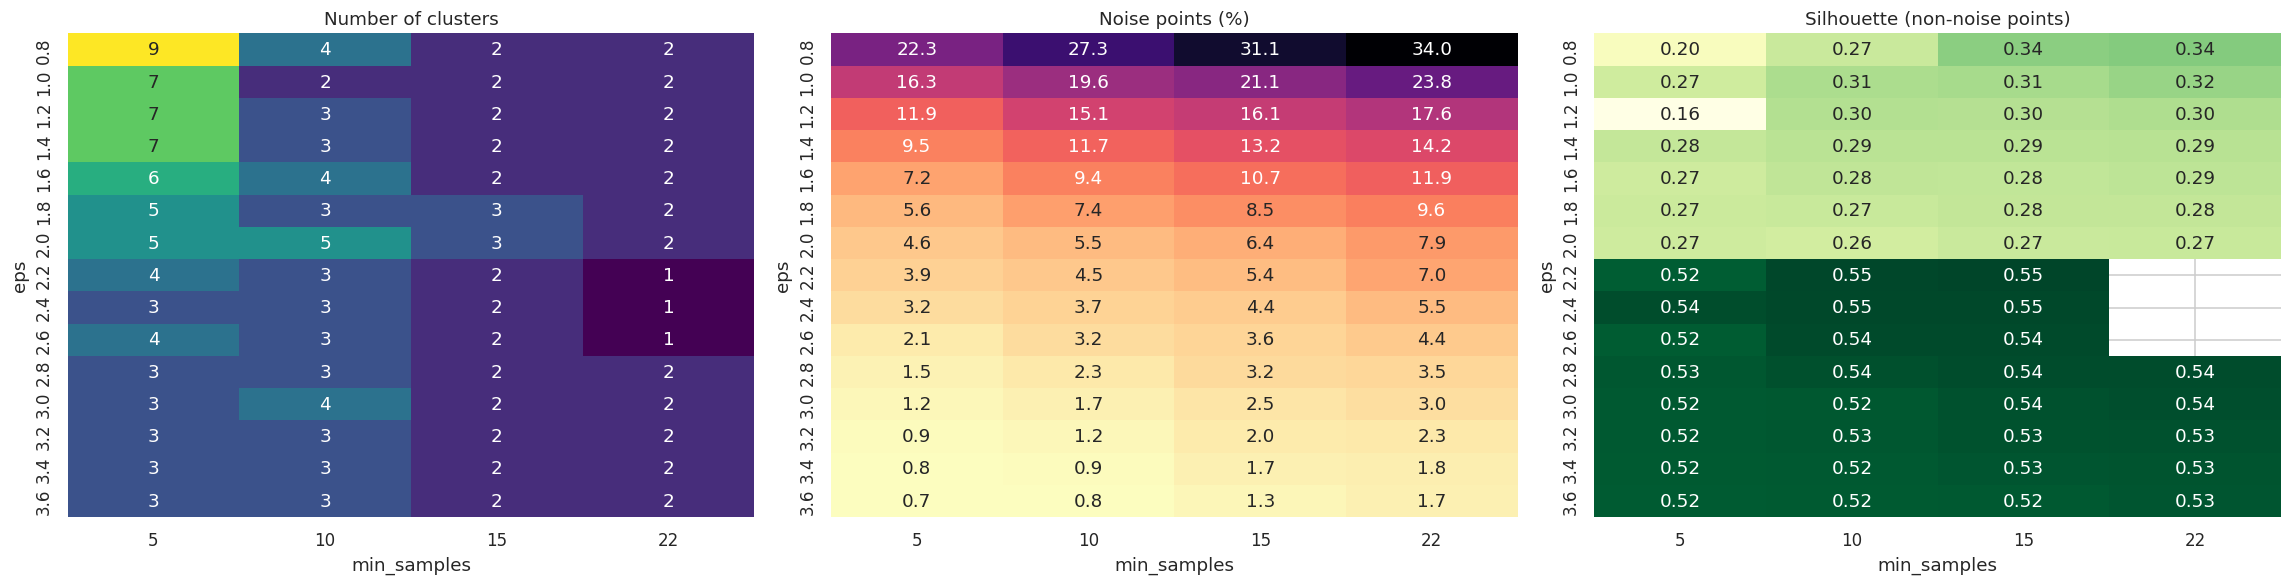

In [28]:
eps_grid = np.round(np.arange(0.8, 3.61, 0.2), 1)
ms_grid = [5, 10, 15, 22]
rows = []
for eps in eps_grid:
    for ms in ms_grid:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        core = lab != -1
        n_clusters = len(set(lab[core]))
        sizes = np.bincount(lab[core]) if n_clusters else np.array([0])
        sil_ = silhouette_score(X[core], lab[core]) if n_clusters > 1 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_clusters,
                     "noise_%": (~core).mean() * 100, "largest_cluster_%_of_clustered": sizes.max() / max(core.sum(), 1) * 100,
                     "silhouette": sil_})
db_grid = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, col, title, fmt, cmap in [(axes[0], "n_clusters", "Number of clusters", ".0f", "viridis"),
                                  (axes[1], "noise_%", "Noise points (%)", ".1f", "magma_r"),
                                  (axes[2], "silhouette", "Silhouette (non-noise points)", ".2f", "YlGn")]:
    sns.heatmap(db_grid.pivot(index="eps", columns="min_samples", values=col), annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

The heatmaps show two regimes:
- **eps <= 2.0**: DBSCAN finds a few clusters (mostly 2 to 7) and the largest one holds about two thirds of the clustered customers. The share of noise falls from about 30 % to under 5 % as eps grows. The silhouette is around 0.2 to 0.3.
- **eps >= 2.2**: the silhouette jumps to about 0.5, but this is misleading. About 99 % of the clustered customers end up in a single giant cluster and only a few dozen extreme customers form tiny clusters. The silhouette is high only because that one blob is internally dense.

To avoid rewarding the trivial one-blob solution, we select the configuration with the **highest silhouette subject to** (a) at least 2 clusters, (b) noise <= 10 % of customers, and (c) the largest cluster holding < 80 % of the clustered points.

In [29]:
eligible = db_grid[(db_grid["n_clusters"] >= 2) & (db_grid["noise_%"] <= 10) &
                   (db_grid["largest_cluster_%_of_clustered"] < 80)].sort_values("silhouette", ascending=False)
display(eligible.round(3).head(8).reset_index(drop=True))
best = eligible.iloc[0]
EPS, MIN_S = float(best["eps"]), int(best["min_samples"])
print(f"Selected: eps = {EPS}, min_samples = {MIN_S}")

Selected: eps = 1.6, min_samples = 10


,eps,min_samples,n_clusters,noise_%,largest_cluster_%_of_clustered,silhouette
0,1.6,10,4,9.433,66.629,0.283
1,1.8,15,3,8.536,66.368,0.280
2,1.8,22,2,9.613,66.903,0.280
3,1.4,5,7,9.485,66.525,0.279
4,1.8,10,3,7.434,66.325,0.275
5,2.0,22,2,7.870,66.361,0.275
6,2.0,15,3,6.357,65.946,0.272
7,1.8,5,5,5.563,65.364,0.271


### 6.3 Final DBSCAN model

Cluster sizes (-1 = noise):
DBSCAN
-1     368
 0    2354
 1    1154
 2      15
 3      10

Noise: 368 customers (9.4%)
Silhouette (non-noise points only): 0.283
Davies-Bouldin (non-noise points)  : 1.086


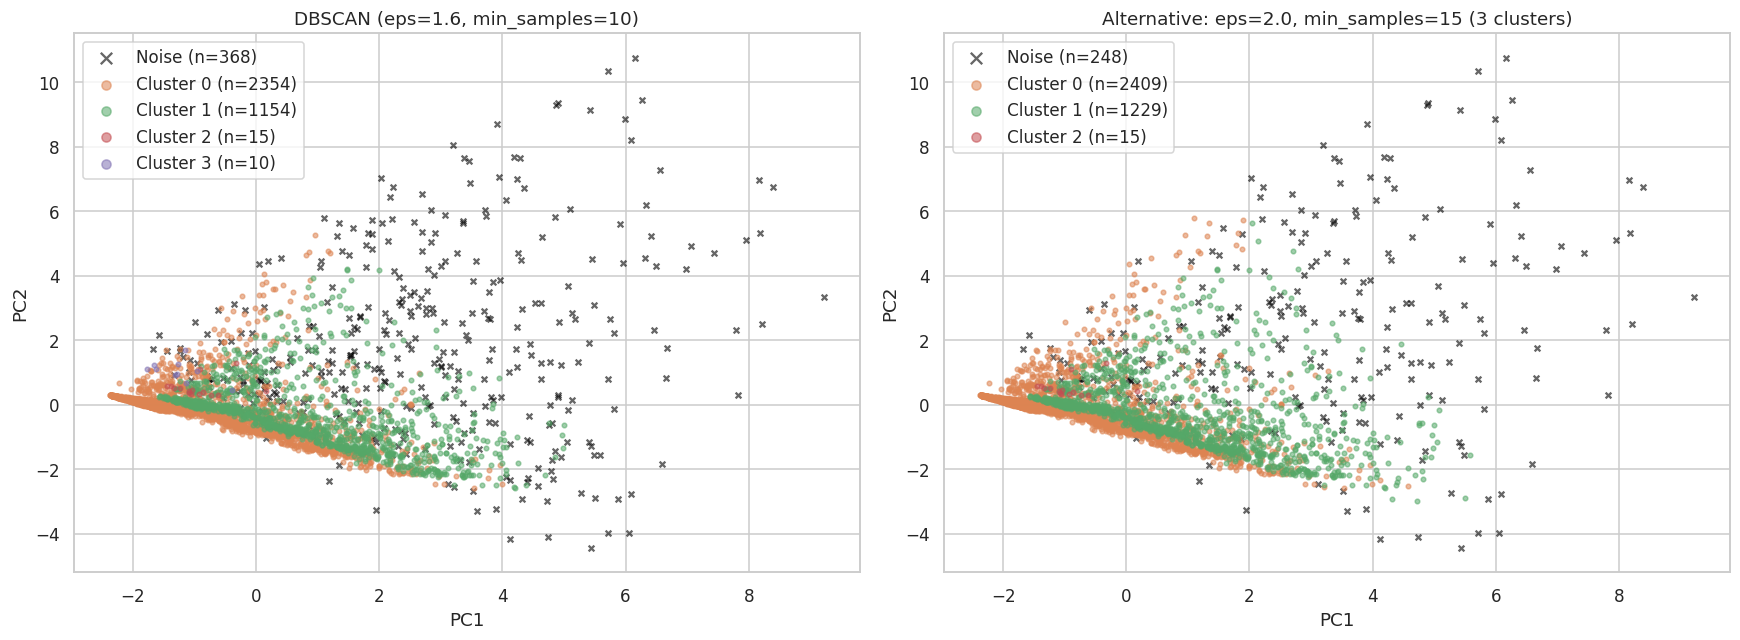

In [30]:
db = DBSCAN(eps=EPS, min_samples=MIN_S).fit(X)
df_clean["DBSCAN"] = db.labels_
core = db.labels_ != -1
print("Cluster sizes (-1 = noise):")
print(df_clean["DBSCAN"].value_counts().sort_index().to_string())
print(f"\nNoise: {(~core).sum()} customers ({(~core).mean():.1%})")
print(f"Silhouette (non-noise points only): {silhouette_score(X[core], db.labels_[core]):.3f}")
print(f"Davies-Bouldin (non-noise points)  : {davies_bouldin_score(X[core], db.labels_[core]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_clusters(db.labels_, f"DBSCAN (eps={EPS}, min_samples={MIN_S})", axes[0])
lab_s = DBSCAN(eps=2.0, min_samples=15).fit_predict(X)
plot_clusters(lab_s, "Alternative: eps=2.0, min_samples=15 (3 clusters)", axes[1])
plt.tight_layout(); plt.show()

,size,share_%,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
DBSCAN,,,,,,,,,,,,,
-1,368,9.4,160136.0,906.5,2.6,1.1,1.1,33576.5,20.3,1991.6,5.9,4589.8,0.7
0,2354,60.3,54606.6,7.3,1.7,1.0,1.0,9429.3,8.6,143.5,0.4,3816.5,0.0
1,1154,29.6,64567.4,13.2,2.6,1.0,1.0,23831.5,13.4,313.9,1.0,4534.9,1.0
2,15,0.4,38556.7,0.0,1.0,2.0,1.0,8951.5,12.9,60.0,0.4,3390.4,0.0
3,10,0.3,26691.7,2327.7,1.1,1.0,1.0,3088.8,5.4,80.0,0.3,2311.7,0.0


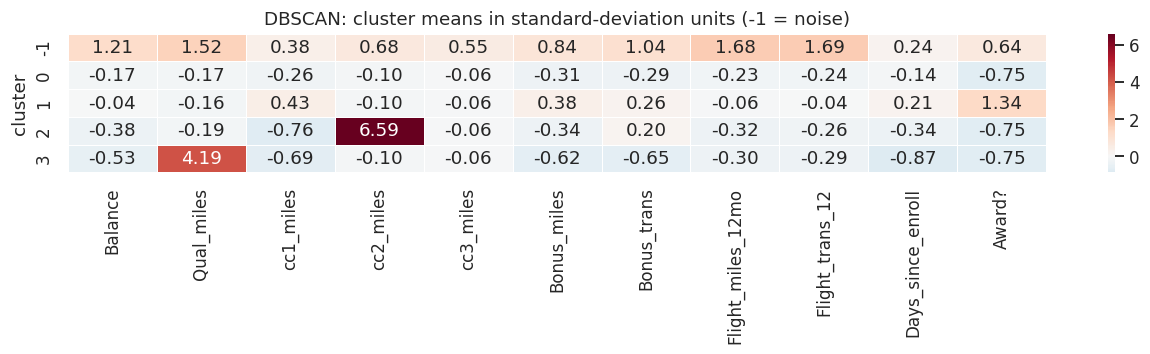

In [31]:
db_profile = profile("DBSCAN")
display(db_profile)
z_prof = pd.DataFrame(X, columns=features).groupby(df_clean["DBSCAN"].values).mean()
plt.figure(figsize=(12, 3.4))
sns.heatmap(z_prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.5)
plt.title("DBSCAN: cluster means in standard-deviation units (-1 = noise)")
plt.ylabel("cluster"); plt.tight_layout(); plt.show()

### 6.4 Interpretation of the DBSCAN segments

| Cluster | Size | What characterises it | Suggested label |
|---|---|---|---|
| **0** | 60 % | Low activity (balance about 55k, bonus miles about 9k, almost no flying), **no customer has redeemed an award** | **Dormant / never redeemed** |
| **1** | 30 % | Higher bonus miles (about 24k) and card bin (~ 2.6), more flying than cluster 0, **every customer has redeemed an award** | **Active redeemers** |
| **2** | 15 customers | All hold a Rewards card (`cc2_miles` = 2) and have no qualifying miles | Niche: Rewards-card holders |
| **3** | 10 customers | Very high qualifying miles (about 2,300) with little other activity and recent enrolment | Niche: status-miles chasers |
| **-1 (noise)** | 9.4 % | The most extreme customers: highest balance (about 160k), most qualifying miles (about 900), most flight miles (about 2,000, 77 % flew), 66 % redeemed | **Outliers = very high-value / heavy flyers** |

DBSCAN's two big clusters are separated almost exactly by the binary `Award?` flag. A binary feature creates a gap in the space, which is exactly what a density-based method needs. In contrast to the other two methods, DBSCAN treats the heavy flyers as **noise** instead of a cluster, and it creates two tiny niche clusters. These tiny groups are interesting for ad-hoc analysis but are too small to be a marketing segment.

## 7. Evaluation and comparison of the algorithms

In [32]:
def evaluate(name, labels, drop_noise=False):
    m = labels != -1 if drop_noise else np.ones(len(labels), bool)
    n_cl = len(set(labels[m]))
    return {"algorithm": name, "clusters": n_cl, "noise_%": round((~m).mean() * 100, 1),
            "silhouette": round(silhouette_score(X[m], labels[m]), 3),
            "davies_bouldin (lower=better)": round(davies_bouldin_score(X[m], labels[m]), 3),
            "calinski_harabasz": round(calinski_harabasz_score(X[m], labels[m]), 1),
            "largest_cluster_%": round(np.bincount(labels[m] - labels[m].min()).max() / m.sum() * 100, 1)}

summary = pd.DataFrame([
    evaluate("K-Means (k=3)", df_clean["KMeans"].values),
    evaluate("Hierarchical Ward (k=3)", df_clean["Hierarchical"].values),
    evaluate(f"DBSCAN (eps={EPS}, min_samples={MIN_S}), non-noise only", df_clean["DBSCAN"].values, drop_noise=True),
]).set_index("algorithm")
summary

,clusters,noise_%,silhouette,davies_bouldin (lower=better),calinski_harabasz,largest_cluster_%
algorithm,,,,,,
K-Means (k=3),3,0.0,0.308,1.387,896.0,62.4
Hierarchical Ward (k=3),3,0.0,0.176,2.121,583.6,46.4
"DBSCAN (eps=1.6, min_samples=10), non-noise only",4,9.4,0.283,1.086,412.7,66.6


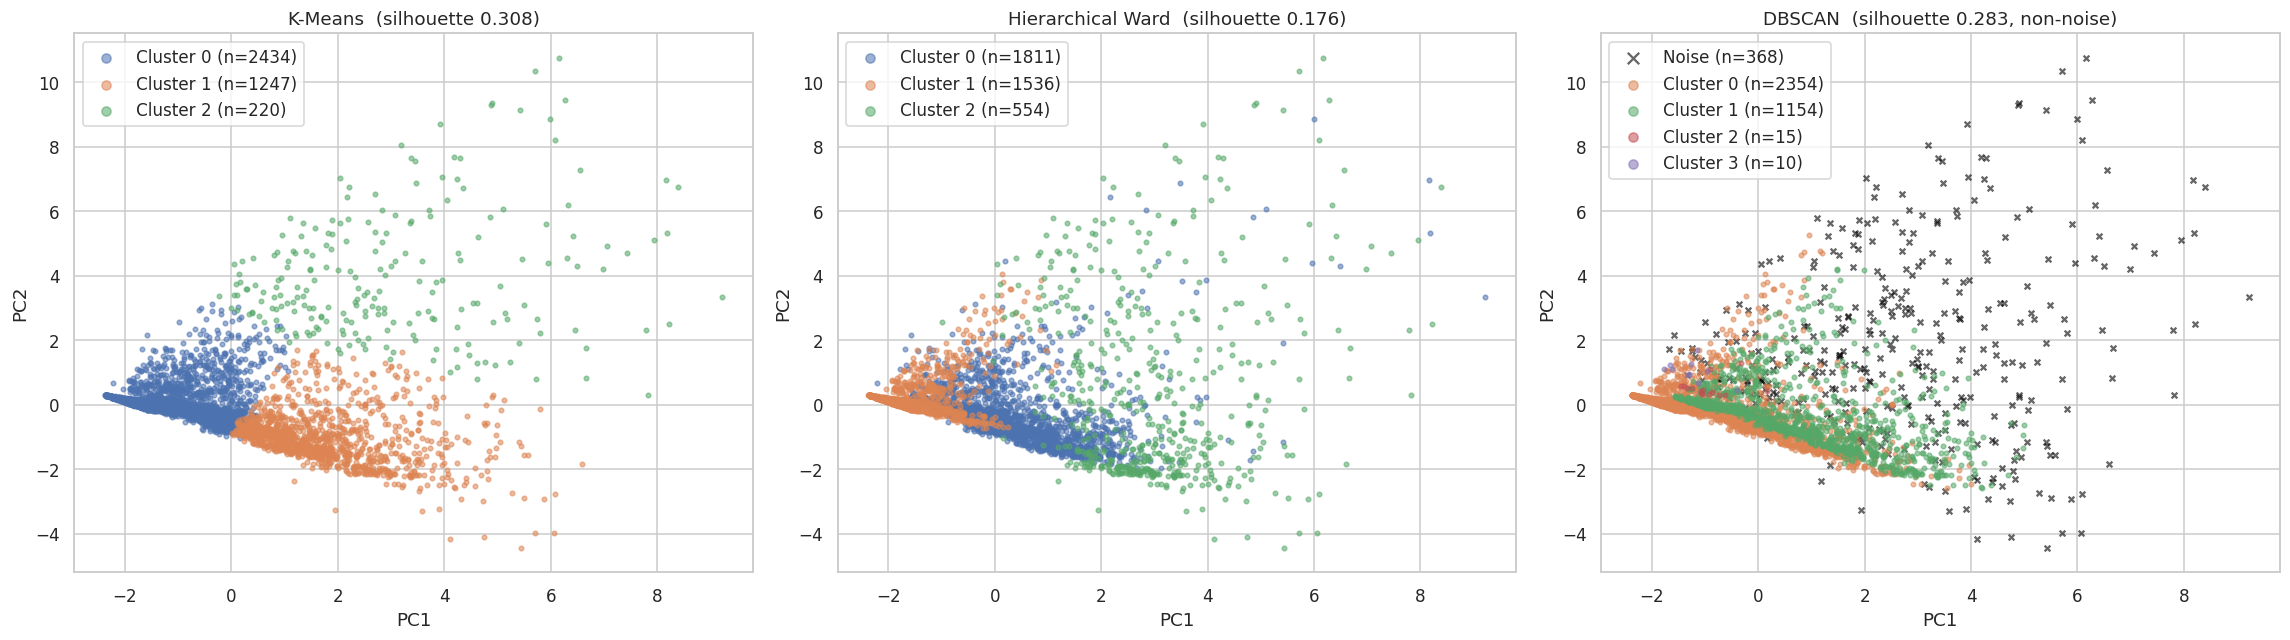

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
plot_clusters(df_clean["KMeans"].values, f"K-Means  (silhouette {silhouette_score(X, df_clean['KMeans']):.3f})", axes[0])
plot_clusters(df_clean["Hierarchical"].values, f"Hierarchical Ward  (silhouette {silhouette_score(X, df_clean['Hierarchical']):.3f})", axes[1])
plot_clusters(df_clean["DBSCAN"].values, f"DBSCAN  (silhouette {silhouette_score(X[core], db.labels_[core]):.3f}, non-noise)", axes[2])
plt.tight_layout(); plt.show()

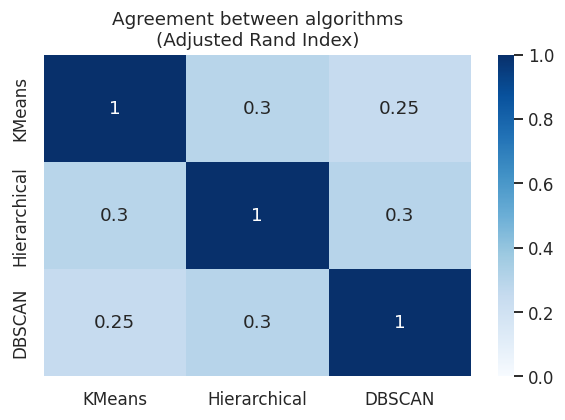

In [34]:
from sklearn.metrics import adjusted_rand_score
ari = pd.DataFrame(
    [[adjusted_rand_score(df_clean[a], df_clean[b]) for b in ["KMeans", "Hierarchical", "DBSCAN"]]
     for a in ["KMeans", "Hierarchical", "DBSCAN"]],
    index=["KMeans", "Hierarchical", "DBSCAN"], columns=["KMeans", "Hierarchical", "DBSCAN"]).round(3)
plt.figure(figsize=(5.5, 4))
sns.heatmap(ari, annot=True, cmap="Blues", vmin=0, vmax=1)
plt.title("Agreement between algorithms\n(Adjusted Rand Index)")
plt.tight_layout(); plt.show()

In [35]:
# How do the K-Means segments relate to the other two algorithms?
print("K-Means vs Hierarchical (rows = K-Means, cols = Ward):")
display(pd.crosstab(df_clean["KMeans"], df_clean["Hierarchical"]))
print("K-Means vs DBSCAN (cols: -1 = noise):")
display(pd.crosstab(df_clean["KMeans"], df_clean["DBSCAN"]))

K-Means vs Hierarchical (rows = K-Means, cols = Ward):
K-Means vs DBSCAN (cols: -1 = noise):


Hierarchical,0,1,2
KMeans,,,
0,907,1520,7
1,872,1,374
2,32,15,173


DBSCAN,-1,0,1,2,3
KMeans,,,,,
0,72,1876,461,15,10
1,135,455,657,0,0
2,161,23,36,0,0


### 7.1 Reading the metrics

| Algorithm | Clusters | Noise | Silhouette | Davies-Bouldin (lower is better) | Comments |
|---|---|---|---|---|---|
| **K-Means (k=3)** | 3 | 0 % | **0.308** | 1.39 | Best silhouette and Calinski-Harabasz; balanced and interpretable |
| **Hierarchical, Ward (k=3)** | 3 | 0 % | 0.176 | 2.12 | Same type of solution as K-Means but with weaker separation, since the clusters touch |
| **DBSCAN (eps=1.6, min_samples=10)** | 4 | 9.4 % | 0.283 | 1.09 | Computed on non-noise points only, so it is **not directly comparable**; two of the four clusters have fewer than 20 customers |

The agreement between the algorithms is low (Adjusted Rand Index of 0.25 to 0.30). This is expected because the customers form a **continuum rather than separate islands**. A silhouette of roughly 0.3 corresponds to a weak-to-moderate cluster structure.

## 8. Conclusions and business insights

**Method**
- The data had no missing values or duplicates. The main preprocessing issue was the extreme right skew of the mileage variables, handled by removing the top 0.5 % tail on each continuous feature (98 customers, 2.5 %) and standardising all features.
- EDA showed two largely separate behaviours: **card / bonus-miles activity** (`cc1_miles`, `Bonus_miles`, `Bonus_trans`, `Balance`, `Award?`) and **actual flying** (`Flight_miles_12mo`, `Flight_trans_12`, `Qual_miles`).
- K-Means: elbow and silhouette favour k = 2 to 4; **k = 3** was chosen as the most informative with a near-best silhouette. Hierarchical clustering: **Ward** linkage was chosen because single, average and complete linkage only isolate a few outliers. DBSCAN: eps and min_samples were chosen from a grid search with constraints that prevent the trivial "one big blob" solution.

**What all three methods agree on.** The East-West customer base consists of
1. a **large low-engagement majority** (about 40 to 60 % of customers) with low balances, few bonus miles, hardly any card use and little flying;
2. a **card / bonus-driven group** (about 30 %) with high balances, long tenure, high credit-card bins and a high rate of award redemption;
3. a **small high-value, flight-heavy group** (about 5 to 14 %; the heavy-flyer "noise" in DBSCAN) with high flight miles, qualifying miles and balances.

**Which model to use?** For customer segmentation we recommend **K-Means with k = 3**: it has the best silhouette and Calinski-Harabasz scores, no noise points, balanced cluster sizes, and the most distinct segment for heavy flyers. DBSCAN is most useful as a complement for flagging unusual customers, and Ward gives the dendrogram, which shows how the segments are nested.

**Possible marketing actions**
- *Low-engagement members:* activation campaigns, welcome offers for the credit card, and easy first-redemption incentives. Only about 20 % have redeemed an award.
- *Card-driven loyalists:* protect and grow this base with card-spend bonuses and redemption offers, since they accumulate the most miles without flying much; they are a prime target for converting spend into flights.
- *Frequent flyers:* status-based perks (Topflight benefits, upgrades) and flight-based promotions, as they are few but the most valuable.

**Limitations.** Silhouette scores around 0.3 show that the segments overlap, so cluster membership should be seen as a tendency rather than a hard boundary. Results depend on preprocessing choices (outlier cut-off, no log-transform) and on the correlated card features, which give the card-activity dimension more weight in the distance. Cluster labels are only meaningful relative to this run (`random_state=42`).